In [1]:
import torch 
print(torch.cuda.is_available)

<function is_available at 0x7fe7f25b4af0>


In [1]:
# ────────────────────────────────────────────────────────────────
# 1) Install / import dependencies
# (Colab already comes with torch, torchvision, etc.)
# ────────────────────────────────────────────────────────────────
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import CelebA
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import random
#%pip install gdown

from tqdm import tqdm

def set_seed(seed: int):
    # 1) Python built-ins
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    # 2) NumPy
    np.random.seed(seed)

    # 3) Torch (CPU & GPU)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # 4) Torch determinism flags
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

    # 5) (Optional, PyTorch ≥1.8) enforce everywhere
    #torch.use_deterministic_algorithms(True)

In [3]:
import torch
import torch.nn as nn

class AEEncoder(nn.Module):
    def __init__(
        self,
        img_channels:    int = 3,
        filters:         int = 64,
        kernel_size:     int = 3,
        intermediate_dim:int = 512,
        latent_dim:      int = 128,
        img_rows:        int = 64,
        img_cols:        int = 64,
    ):
        super().__init__()
        pad = kernel_size // 2

        # three downsampling steps: 64→32→16→8
        self.conv1 = nn.Conv2d(img_channels, filters,     kernel_size,
                               stride=2, padding=pad)
        self.bn1   = nn.BatchNorm2d(filters)
        self.conv2 = nn.Conv2d(filters,      filters*2,  kernel_size,
                               stride=2, padding=pad)
        self.bn2   = nn.BatchNorm2d(filters*2)
        self.conv3 = nn.Conv2d(filters*2,    filters*4,  kernel_size,
                               stride=2, padding=pad)
        self.bn3   = nn.BatchNorm2d(filters*4)
        self.act   = nn.ReLU(inplace=True)

        # compute flattened size at 8×8
        down = 2**3
        h, w = img_rows // down, img_cols // down
        flat_dim = filters*4 * h * w

        self.flatten   = nn.Flatten()
        self.fc_shared = nn.Linear(flat_dim, intermediate_dim)
        self.fc_latent = nn.Linear(intermediate_dim, latent_dim)

    def forward(self, x):
        x = self.act(self.bn1(self.conv1(x)))  # → [B,   F, 32, 32]
        x = self.act(self.bn2(self.conv2(x)))  # → [B, 2F, 16, 16]
        x = self.act(self.bn3(self.conv3(x)))  # → [B, 4F,  8,  8]
        x = self.flatten(x)                    # → [B, 4F*8*8]
        h = self.act(self.fc_shared(x))        # → [B, intermediate_dim]
        z = self.fc_latent(h)                  # → [B, latent_dim]
        return z


class AEDecoder(nn.Module):
    def __init__(
        self,
        img_channels:    int = 3,
        filters:         int = 64,
        latent_dim:      int = 128,
        intermediate_dim:int = 512,
        img_rows:        int = 64,
        img_cols:        int = 64,
    ):
        super().__init__()
        down = 2**3
        h, w = img_rows // down, img_cols // down
        # project latent → feature map
        self.fc1 = nn.Linear(latent_dim, intermediate_dim)
        self.fc2 = nn.Linear(intermediate_dim, filters*4 * h * w)
        self.act = nn.ReLU(inplace=True)
        self.reshape = lambda z: z.view(-1, filters*4, h, w)

        # three upsampling steps:  8→16→32→64
        self.deconv1 = nn.ConvTranspose2d(filters*4, filters*2,
                                          kernel_size=4, stride=2, padding=1)
        self.bn1      = nn.BatchNorm2d(filters*2)
        self.deconv2 = nn.ConvTranspose2d(filters*2, filters,
                                          kernel_size=4, stride=2, padding=1)
        self.bn2      = nn.BatchNorm2d(filters)
        self.deconv3 = nn.ConvTranspose2d(filters, img_channels,
                                          kernel_size=4, stride=2, padding=1)

        # match your CelebA normalization
        self.out_act = nn.Tanh()  

    def forward(self, z):
        h = self.act(self.fc1(z))              # → [B, intermediate_dim]
        h = self.act(self.fc2(h))              # → [B, 4F*8*8]
        h = self.reshape(h)                    # → [B,4F, 8,8]
        h = self.act(self.bn1(self.deconv1(h)))# → [B,2F,16,16]
        h = self.act(self.bn2(self.deconv2(h)))# → [B,  F,32,32]
        x_hat = self.out_act(self.deconv3(h))  # → [B,3,64,64]
        return x_hat


class Autoencoder(nn.Module):
    def __init__(
        self,
        img_channels:    int = 3,
        filters:         int = 64,
        kernel_size:     int = 3,
        intermediate_dim:int = 512,
        latent_dim:      int = 128,
        img_rows:        int = 64,
        img_cols:        int = 64,
    ):
        super().__init__()
        self.encoder = AEEncoder(
            img_channels=img_channels,
            filters=filters,
            kernel_size=kernel_size,
            intermediate_dim=intermediate_dim,
            latent_dim=latent_dim,
            img_rows=img_rows,
            img_cols=img_cols,
        )
        self.decoder = AEDecoder(
            img_channels=img_channels,
            filters=filters,
            latent_dim=latent_dim,
            intermediate_dim=intermediate_dim,
            img_rows=img_rows,
            img_cols=img_cols,
        )

    def forward(self, x):
        z     = self.encoder(x)
        x_hat = self.decoder(z)
        return z, x_hat


Files already downloaded and verified
Current CUDA device: 1 NVIDIA GeForce GTX TITAN X
[Epoch 1/80  Step 200]  Reconstruction=0.09140  MMD=0.94154 IMM=0.02183
[Epoch 1/80  Step 400]  Reconstruction=0.07499  MMD=0.65851 IMM=0.03542
[Epoch 1/80  Step 600]  Reconstruction=0.06057  MMD=0.53983 IMM=0.02136
[Epoch 1/80  Step 800]  Reconstruction=0.05013  MMD=0.47094 IMM=0.00990
[Epoch 1/80  Step 1000]  Reconstruction=0.04749  MMD=0.47382 IMM=0.00982


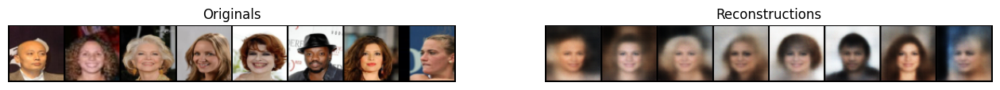

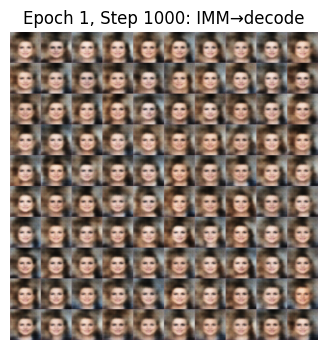

[Epoch 1/80  Step 1200]  Reconstruction=0.04393  MMD=0.45737 IMM=0.02570
[Epoch 2/80  Step 1400]  Reconstruction=0.04047  MMD=0.43961 IMM=0.02637
[Epoch 2/80  Step 1600]  Reconstruction=0.04125  MMD=0.43907 IMM=0.02425
[Epoch 2/80  Step 1800]  Reconstruction=0.03875  MMD=0.45323 IMM=0.00734
[Epoch 2/80  Step 2000]  Reconstruction=0.03703  MMD=0.46570 IMM=0.01003


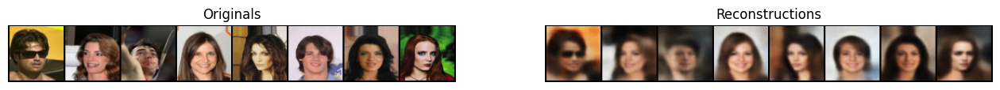

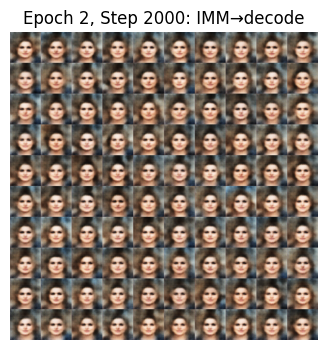

[Epoch 2/80  Step 2200]  Reconstruction=0.03429  MMD=0.48580 IMM=0.00903
[Epoch 2/80  Step 2400]  Reconstruction=0.03408  MMD=0.48709 IMM=-0.00060
[Epoch 3/80  Step 2600]  Reconstruction=0.03525  MMD=0.51778 IMM=0.01482
[Epoch 3/80  Step 2800]  Reconstruction=0.03358  MMD=0.51509 IMM=0.01329
[Epoch 3/80  Step 3000]  Reconstruction=0.03231  MMD=0.54218 IMM=0.04005


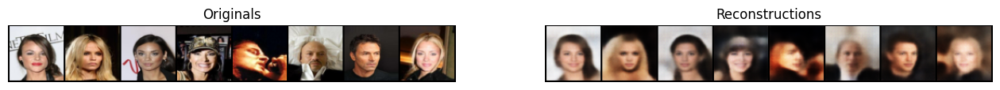

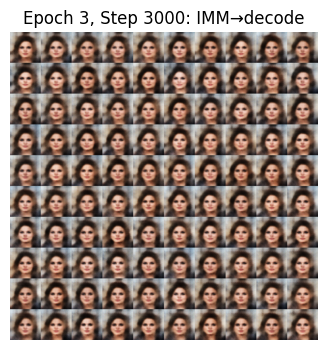

[Epoch 3/80  Step 3200]  Reconstruction=0.03065  MMD=0.51855 IMM=0.00528
[Epoch 3/80  Step 3400]  Reconstruction=0.03477  MMD=0.56587 IMM=0.07631
[Epoch 3/80  Step 3600]  Reconstruction=0.03050  MMD=0.53771 IMM=0.01174
[Epoch 3/80  Step 3800]  Reconstruction=0.02863  MMD=0.51305 IMM=0.03009
[Epoch 4/80  Step 4000]  Reconstruction=0.02799  MMD=0.52682 IMM=0.05198


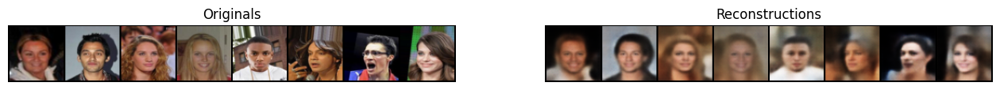

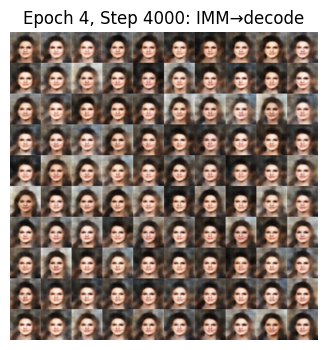

[Epoch 4/80  Step 4200]  Reconstruction=0.02861  MMD=0.50952 IMM=0.02976
[Epoch 4/80  Step 4400]  Reconstruction=0.02883  MMD=0.54624 IMM=0.01169
[Epoch 4/80  Step 4600]  Reconstruction=0.02712  MMD=0.53432 IMM=0.03761
[Epoch 4/80  Step 4800]  Reconstruction=0.02550  MMD=0.50417 IMM=0.06212
[Epoch 4/80  Step 5000]  Reconstruction=0.02569  MMD=0.53866 IMM=0.02852


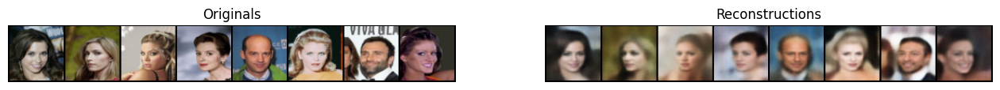

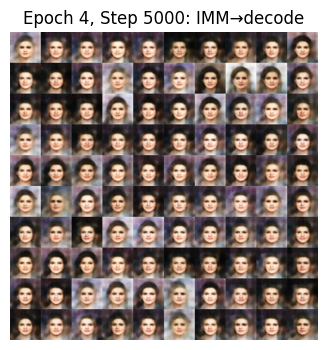

[Epoch 5/80  Step 5200]  Reconstruction=0.02629  MMD=0.60701 IMM=0.06002
[Epoch 5/80  Step 5400]  Reconstruction=0.02608  MMD=0.63207 IMM=0.05841
[Epoch 5/80  Step 5600]  Reconstruction=0.02579  MMD=0.55339 IMM=0.04660
[Epoch 5/80  Step 5800]  Reconstruction=0.02447  MMD=0.61038 IMM=0.04284
[Epoch 5/80  Step 6000]  Reconstruction=0.02604  MMD=0.66532 IMM=0.01559


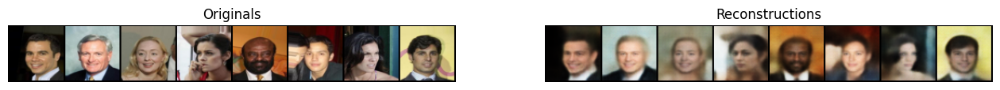

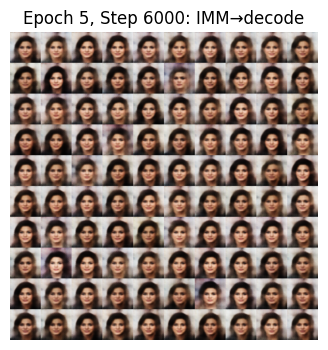

[Epoch 5/80  Step 6200]  Reconstruction=0.02510  MMD=0.51894 IMM=0.03820
[Epoch 6/80  Step 6400]  Reconstruction=0.02614  MMD=0.58445 IMM=0.00638
[Epoch 6/80  Step 6600]  Reconstruction=0.02406  MMD=0.62914 IMM=0.00679
[Epoch 6/80  Step 6800]  Reconstruction=0.02515  MMD=0.56462 IMM=0.07067
[Epoch 6/80  Step 7000]  Reconstruction=0.02513  MMD=0.61927 IMM=0.01508


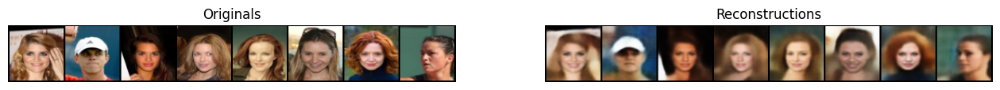

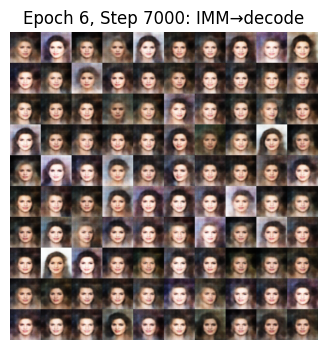

[Epoch 6/80  Step 7200]  Reconstruction=0.02301  MMD=0.43960 IMM=0.02747
[Epoch 6/80  Step 7400]  Reconstruction=0.02343  MMD=0.51034 IMM=0.01997
[Epoch 6/80  Step 7600]  Reconstruction=0.02315  MMD=0.65926 IMM=0.00300
[Epoch 7/80  Step 7800]  Reconstruction=0.02383  MMD=0.49017 IMM=0.05003
[Epoch 7/80  Step 8000]  Reconstruction=0.02299  MMD=0.49880 IMM=0.04467


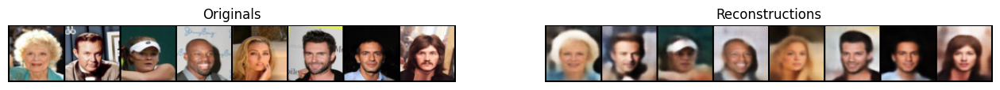

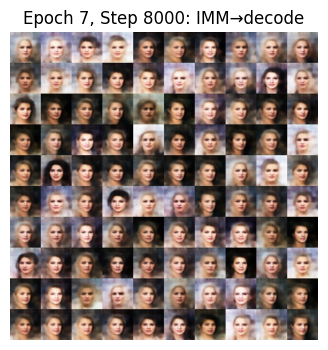

[Epoch 7/80  Step 8200]  Reconstruction=0.02495  MMD=0.69037 IMM=0.00446
[Epoch 7/80  Step 8400]  Reconstruction=0.02404  MMD=0.56057 IMM=0.10806
[Epoch 7/80  Step 8600]  Reconstruction=0.02311  MMD=0.49395 IMM=0.08792
[Epoch 7/80  Step 8800]  Reconstruction=0.02293  MMD=0.48749 IMM=0.02600
[Epoch 8/80  Step 9000]  Reconstruction=0.02290  MMD=0.38419 IMM=0.03257


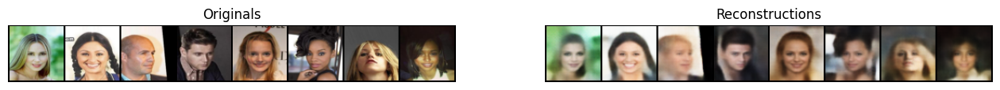

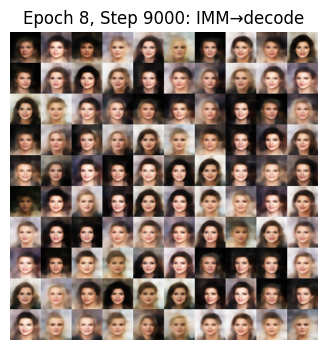

[Epoch 8/80  Step 9200]  Reconstruction=0.02190  MMD=0.69592 IMM=0.01976
[Epoch 8/80  Step 9400]  Reconstruction=0.02171  MMD=0.51900 IMM=0.02613
[Epoch 8/80  Step 9600]  Reconstruction=0.02180  MMD=0.39181 IMM=0.00552
[Epoch 8/80  Step 9800]  Reconstruction=0.02342  MMD=0.59328 IMM=0.03489
[Epoch 8/80  Step 10000]  Reconstruction=0.02235  MMD=0.37903 IMM=0.15213


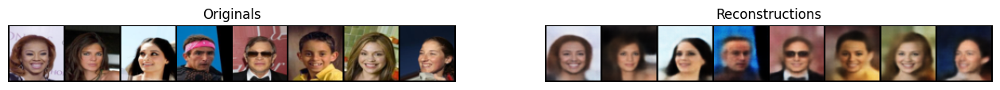

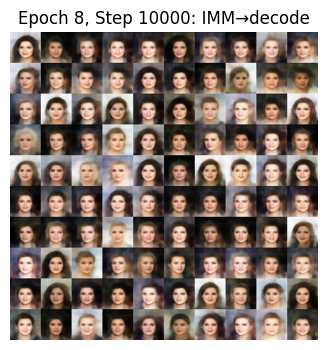

[Epoch 9/80  Step 10200]  Reconstruction=0.02283  MMD=0.71779 IMM=-0.00049
[Epoch 9/80  Step 10400]  Reconstruction=0.02326  MMD=0.51167 IMM=-0.00103
[Epoch 9/80  Step 10600]  Reconstruction=0.02206  MMD=0.26326 IMM=0.03732
[Epoch 9/80  Step 10800]  Reconstruction=0.02125  MMD=0.37460 IMM=0.03536
[Epoch 9/80  Step 11000]  Reconstruction=0.02152  MMD=0.42545 IMM=0.00068


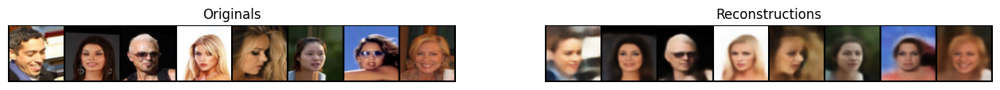

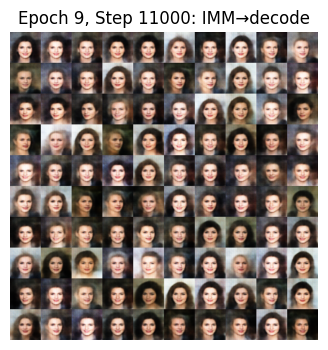

[Epoch 9/80  Step 11200]  Reconstruction=0.02113  MMD=0.61534 IMM=0.02740
[Epoch 9/80  Step 11400]  Reconstruction=0.02164  MMD=0.66356 IMM=0.01774
[Epoch 10/80  Step 11600]  Reconstruction=0.02145  MMD=0.32504 IMM=0.15796
[Epoch 10/80  Step 11800]  Reconstruction=0.02000  MMD=0.27242 IMM=0.00569
[Epoch 10/80  Step 12000]  Reconstruction=0.02337  MMD=0.32175 IMM=0.08840


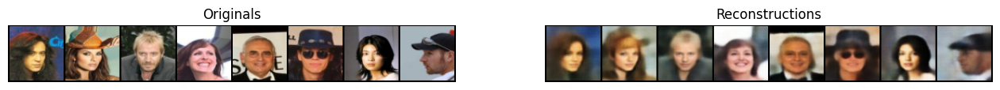

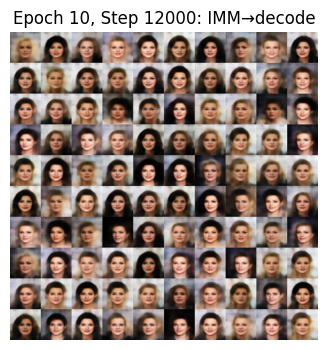

[Epoch 10/80  Step 12200]  Reconstruction=0.02102  MMD=0.26453 IMM=0.03175
[Epoch 10/80  Step 12400]  Reconstruction=0.02110  MMD=0.63917 IMM=0.03109
[Epoch 10/80  Step 12600]  Reconstruction=0.02143  MMD=0.32467 IMM=0.05918
[Epoch 11/80  Step 12800]  Reconstruction=0.02013  MMD=0.43491 IMM=0.01070
[Epoch 11/80  Step 13000]  Reconstruction=0.01945  MMD=0.42668 IMM=0.01345


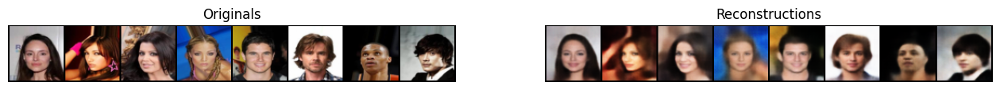

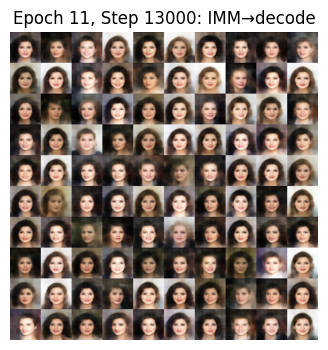

[Epoch 11/80  Step 13200]  Reconstruction=0.02149  MMD=0.40925 IMM=0.02029
[Epoch 11/80  Step 13400]  Reconstruction=0.02050  MMD=0.50954 IMM=0.06038
[Epoch 11/80  Step 13600]  Reconstruction=0.02081  MMD=0.28738 IMM=0.02673
[Epoch 11/80  Step 13800]  Reconstruction=0.02027  MMD=0.52413 IMM=0.06142
[Epoch 12/80  Step 14000]  Reconstruction=0.01949  MMD=0.34853 IMM=0.06464


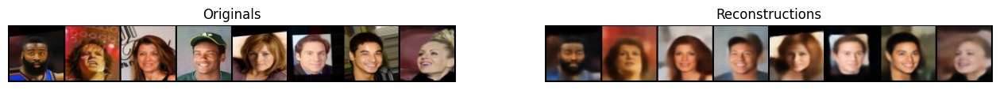

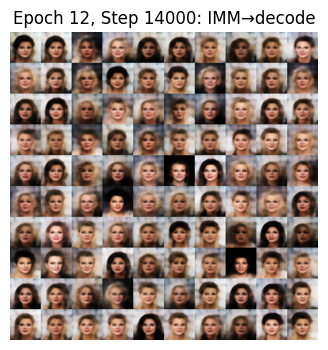

[Epoch 12/80  Step 14200]  Reconstruction=0.02122  MMD=0.31170 IMM=0.02965
[Epoch 12/80  Step 14400]  Reconstruction=0.01882  MMD=0.25867 IMM=0.02564
[Epoch 12/80  Step 14600]  Reconstruction=0.02072  MMD=0.26527 IMM=0.02882
[Epoch 12/80  Step 14800]  Reconstruction=0.02130  MMD=0.54485 IMM=0.08085
[Epoch 12/80  Step 15000]  Reconstruction=0.02167  MMD=0.20532 IMM=0.09806


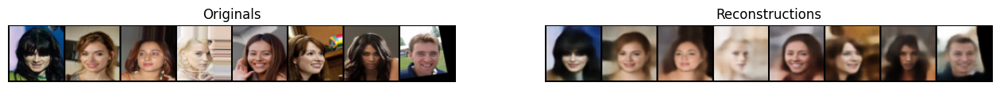

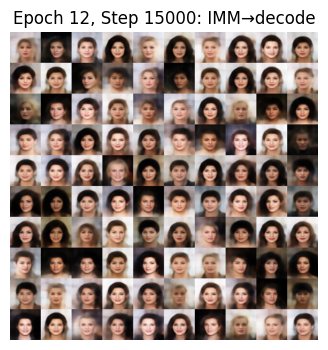

[Epoch 12/80  Step 15200]  Reconstruction=0.02039  MMD=0.42373 IMM=0.00609
[Epoch 13/80  Step 15400]  Reconstruction=0.01896  MMD=0.56416 IMM=0.09805
[Epoch 13/80  Step 15600]  Reconstruction=0.01924  MMD=0.19216 IMM=0.00823
[Epoch 13/80  Step 15800]  Reconstruction=0.02067  MMD=0.20645 IMM=0.01157
[Epoch 13/80  Step 16000]  Reconstruction=0.02062  MMD=0.16918 IMM=0.00459


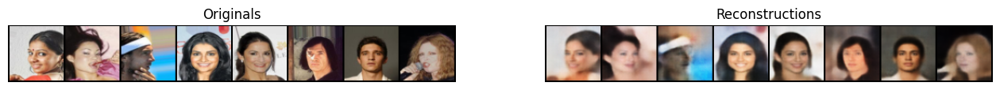

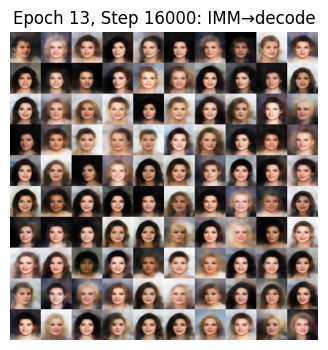

[Epoch 13/80  Step 16200]  Reconstruction=0.01933  MMD=0.43987 IMM=0.00765
[Epoch 13/80  Step 16400]  Reconstruction=0.02189  MMD=0.35539 IMM=0.04502
[Epoch 14/80  Step 16600]  Reconstruction=0.01840  MMD=0.33585 IMM=0.03457
[Epoch 14/80  Step 16800]  Reconstruction=0.01944  MMD=0.52383 IMM=0.03529
[Epoch 14/80  Step 17000]  Reconstruction=0.01979  MMD=0.19995 IMM=0.04245


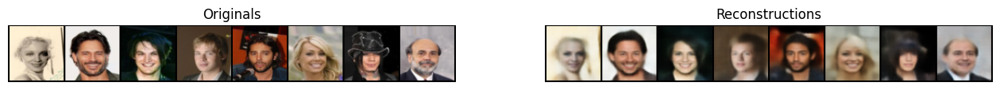

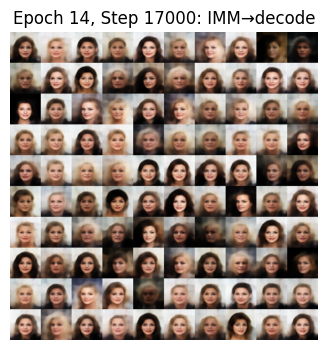

[Epoch 14/80  Step 17200]  Reconstruction=0.02197  MMD=0.56193 IMM=0.05482
[Epoch 14/80  Step 17400]  Reconstruction=0.01884  MMD=0.59656 IMM=0.06532
[Epoch 14/80  Step 17600]  Reconstruction=0.02142  MMD=0.20835 IMM=0.01218
[Epoch 15/80  Step 17800]  Reconstruction=0.01982  MMD=0.22371 IMM=0.07529
[Epoch 15/80  Step 18000]  Reconstruction=0.01937  MMD=0.21955 IMM=0.05369


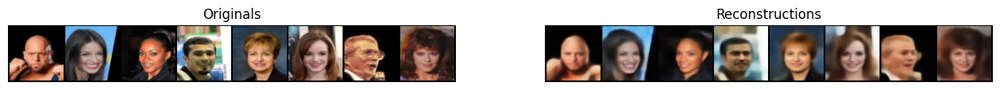

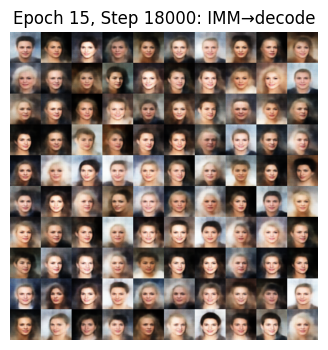

[Epoch 15/80  Step 18200]  Reconstruction=0.02057  MMD=0.22966 IMM=0.11398
[Epoch 15/80  Step 18400]  Reconstruction=0.01983  MMD=0.15825 IMM=0.05401
[Epoch 15/80  Step 18600]  Reconstruction=0.01919  MMD=0.26399 IMM=0.02768
[Epoch 15/80  Step 18800]  Reconstruction=0.02091  MMD=0.27446 IMM=0.05870
[Epoch 15/80  Step 19000]  Reconstruction=0.01910  MMD=0.15165 IMM=0.10872


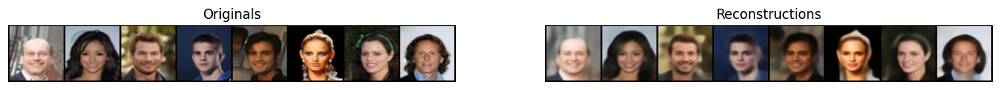

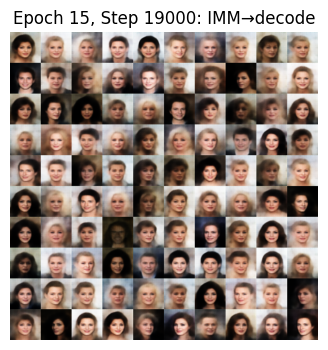

[Epoch 16/80  Step 19200]  Reconstruction=0.01757  MMD=0.16243 IMM=0.03024
[Epoch 16/80  Step 19400]  Reconstruction=0.02015  MMD=0.17720 IMM=0.07372
[Epoch 16/80  Step 19600]  Reconstruction=0.02007  MMD=0.27211 IMM=0.01904
[Epoch 16/80  Step 19800]  Reconstruction=0.01953  MMD=0.26019 IMM=0.03235
[Epoch 16/80  Step 20000]  Reconstruction=0.01910  MMD=0.35472 IMM=0.01249


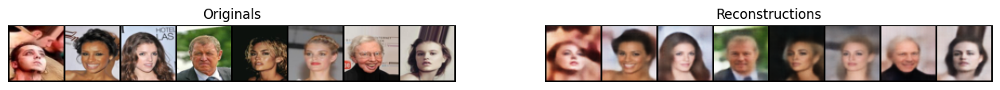

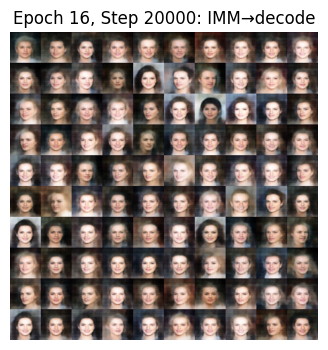

[Epoch 16/80  Step 20200]  Reconstruction=0.01928  MMD=0.30610 IMM=0.02363
[Epoch 17/80  Step 20400]  Reconstruction=0.01863  MMD=0.17279 IMM=0.03755
[Epoch 17/80  Step 20600]  Reconstruction=0.02002  MMD=0.21777 IMM=0.03035
[Epoch 17/80  Step 20800]  Reconstruction=0.01870  MMD=0.11482 IMM=0.04283
[Epoch 17/80  Step 21000]  Reconstruction=0.01890  MMD=0.32405 IMM=0.13712


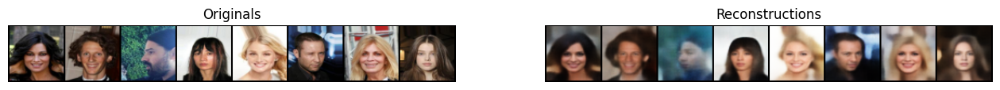

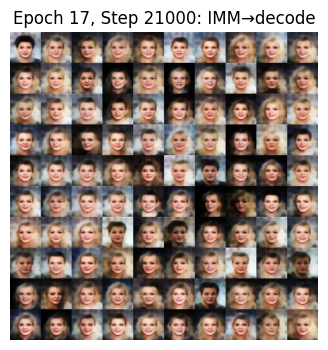

[Epoch 17/80  Step 21200]  Reconstruction=0.01761  MMD=0.30541 IMM=0.05362
[Epoch 17/80  Step 21400]  Reconstruction=0.01856  MMD=0.24721 IMM=0.06374
[Epoch 17/80  Step 21600]  Reconstruction=0.01796  MMD=0.27791 IMM=0.03259
[Epoch 18/80  Step 21800]  Reconstruction=0.01929  MMD=0.33499 IMM=0.10256
[Epoch 18/80  Step 22000]  Reconstruction=0.01777  MMD=0.09533 IMM=0.03591


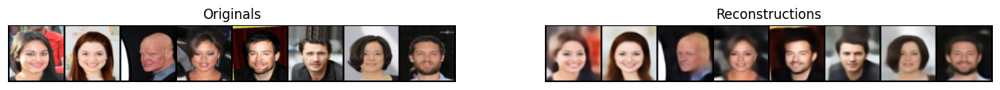

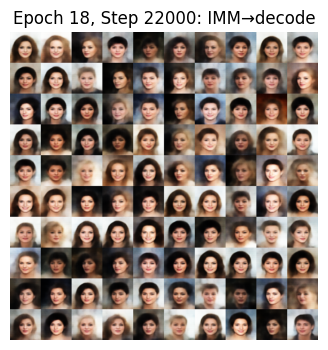

[Epoch 18/80  Step 22200]  Reconstruction=0.01768  MMD=0.09924 IMM=0.08833
[Epoch 18/80  Step 22400]  Reconstruction=0.02043  MMD=0.06457 IMM=0.02249
[Epoch 18/80  Step 22600]  Reconstruction=0.01869  MMD=0.10327 IMM=0.01971
[Epoch 18/80  Step 22800]  Reconstruction=0.01832  MMD=0.17924 IMM=0.04808
[Epoch 19/80  Step 23000]  Reconstruction=0.01905  MMD=0.11769 IMM=0.02726


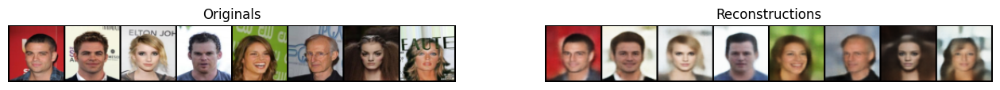

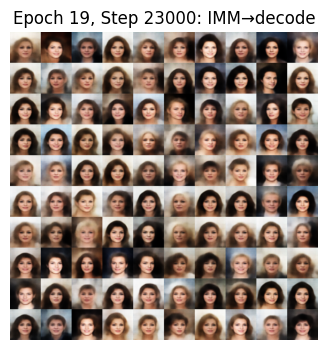

[Epoch 19/80  Step 23200]  Reconstruction=0.02013  MMD=0.16271 IMM=0.08014
[Epoch 19/80  Step 23400]  Reconstruction=0.01858  MMD=0.07378 IMM=0.03415
[Epoch 19/80  Step 23600]  Reconstruction=0.01813  MMD=0.18013 IMM=0.05550
[Epoch 19/80  Step 23800]  Reconstruction=0.01655  MMD=0.12345 IMM=0.05161
[Epoch 19/80  Step 24000]  Reconstruction=0.01995  MMD=0.16160 IMM=0.11391


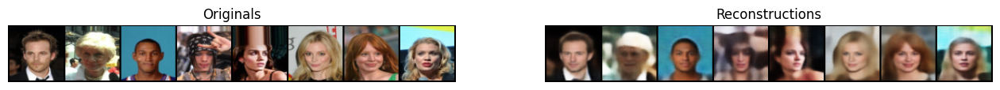

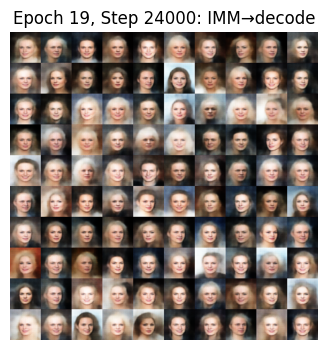

[Epoch 20/80  Step 24200]  Reconstruction=0.01761  MMD=0.16720 IMM=0.03314
[Epoch 20/80  Step 24400]  Reconstruction=0.01926  MMD=0.10389 IMM=0.04390
[Epoch 20/80  Step 24600]  Reconstruction=0.01805  MMD=0.05210 IMM=0.06059
[Epoch 20/80  Step 24800]  Reconstruction=0.01861  MMD=0.09770 IMM=0.04134
[Epoch 20/80  Step 25000]  Reconstruction=0.01858  MMD=0.07675 IMM=0.10420


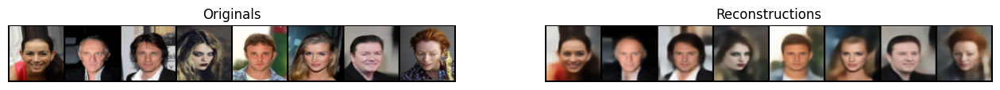

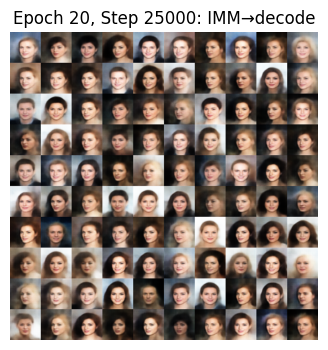

[Epoch 20/80  Step 25200]  Reconstruction=0.01957  MMD=0.09809 IMM=0.09712
[Epoch 20/80  Step 25400]  Reconstruction=0.01811  MMD=0.07158 IMM=0.08669
[Epoch 21/80  Step 25600]  Reconstruction=0.01717  MMD=0.07300 IMM=0.02713
[Epoch 21/80  Step 25800]  Reconstruction=0.01629  MMD=0.07964 IMM=0.02949
[Epoch 21/80  Step 26000]  Reconstruction=0.01831  MMD=0.13837 IMM=0.03673


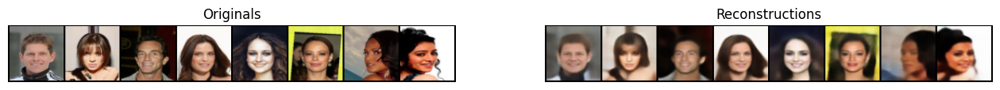

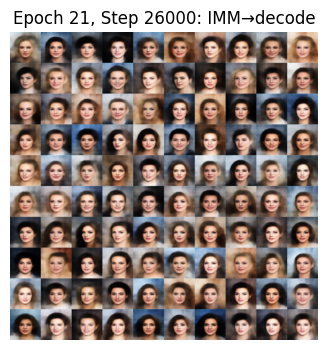

[Epoch 21/80  Step 26200]  Reconstruction=0.01761  MMD=0.07730 IMM=0.01455
[Epoch 21/80  Step 26400]  Reconstruction=0.01792  MMD=0.03919 IMM=0.07334
[Epoch 21/80  Step 26600]  Reconstruction=0.01670  MMD=0.10061 IMM=0.06912
[Epoch 22/80  Step 26800]  Reconstruction=0.01764  MMD=0.24529 IMM=0.05745
[Epoch 22/80  Step 27000]  Reconstruction=0.01931  MMD=0.20502 IMM=0.07019


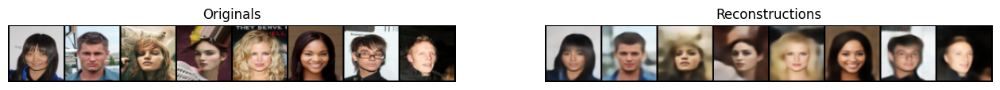

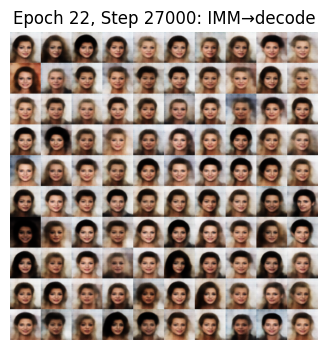

[Epoch 22/80  Step 27200]  Reconstruction=0.01723  MMD=0.08947 IMM=0.04611
[Epoch 22/80  Step 27400]  Reconstruction=0.01889  MMD=0.07859 IMM=0.04863
[Epoch 22/80  Step 27600]  Reconstruction=0.01825  MMD=0.24839 IMM=0.00122
[Epoch 22/80  Step 27800]  Reconstruction=0.01933  MMD=0.07805 IMM=0.04024
[Epoch 23/80  Step 28000]  Reconstruction=0.01706  MMD=0.13840 IMM=0.04884


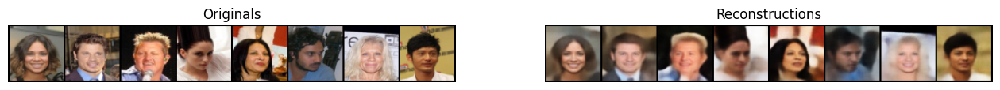

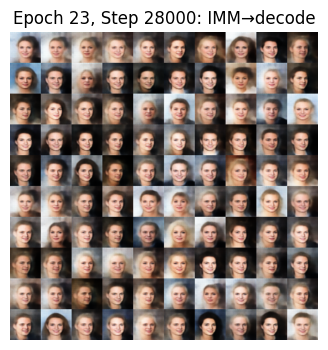

[Epoch 23/80  Step 28200]  Reconstruction=0.01861  MMD=0.22112 IMM=0.00825
[Epoch 23/80  Step 28400]  Reconstruction=0.01746  MMD=0.13175 IMM=0.03993
[Epoch 23/80  Step 28600]  Reconstruction=0.01843  MMD=0.10441 IMM=0.00961
[Epoch 23/80  Step 28800]  Reconstruction=0.01728  MMD=0.12143 IMM=0.10603
[Epoch 23/80  Step 29000]  Reconstruction=0.01872  MMD=0.03796 IMM=0.05794


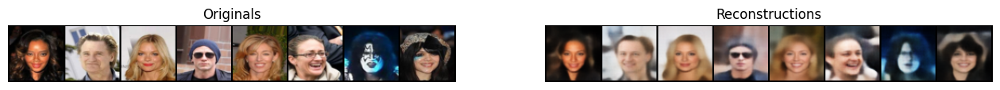

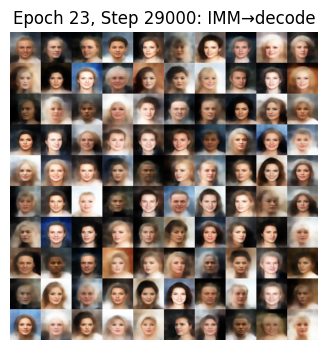

[Epoch 23/80  Step 29200]  Reconstruction=0.01773  MMD=0.12102 IMM=0.01246
[Epoch 24/80  Step 29400]  Reconstruction=0.01727  MMD=0.26299 IMM=0.05870
[Epoch 24/80  Step 29600]  Reconstruction=0.01837  MMD=0.15376 IMM=0.06520
[Epoch 24/80  Step 29800]  Reconstruction=0.01802  MMD=0.03907 IMM=0.02266
[Epoch 24/80  Step 30000]  Reconstruction=0.01907  MMD=0.02964 IMM=0.05361


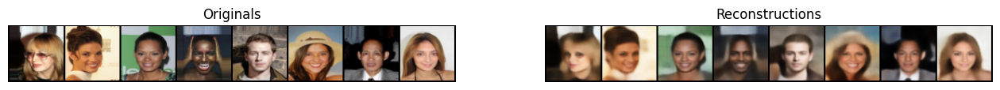

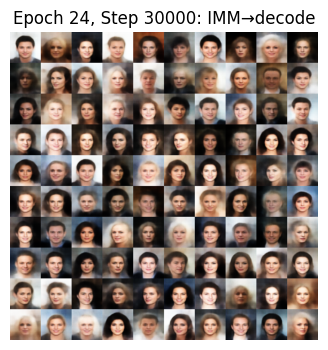

[Epoch 24/80  Step 30200]  Reconstruction=0.01831  MMD=0.02726 IMM=0.04237
[Epoch 24/80  Step 30400]  Reconstruction=0.01820  MMD=0.03889 IMM=0.01098
[Epoch 25/80  Step 30600]  Reconstruction=0.01929  MMD=0.02829 IMM=0.08198
[Epoch 25/80  Step 30800]  Reconstruction=0.01595  MMD=0.03741 IMM=0.02756
[Epoch 25/80  Step 31000]  Reconstruction=0.01578  MMD=0.02978 IMM=0.06909


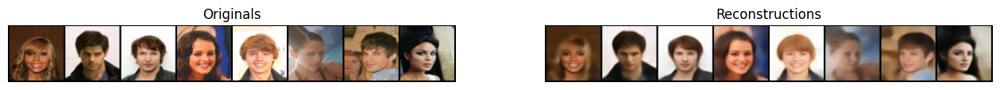

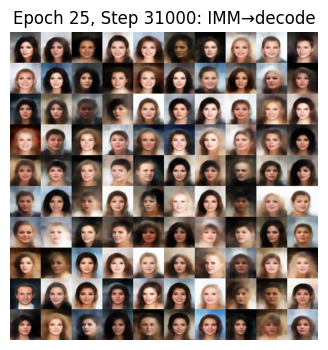

[Epoch 25/80  Step 31200]  Reconstruction=0.01838  MMD=0.05191 IMM=0.07168
[Epoch 25/80  Step 31400]  Reconstruction=0.01739  MMD=0.36882 IMM=0.02238
[Epoch 25/80  Step 31600]  Reconstruction=0.01702  MMD=0.04432 IMM=0.04902
[Epoch 26/80  Step 31800]  Reconstruction=0.01870  MMD=0.03930 IMM=0.05208
[Epoch 26/80  Step 32000]  Reconstruction=0.01683  MMD=0.16983 IMM=0.03921


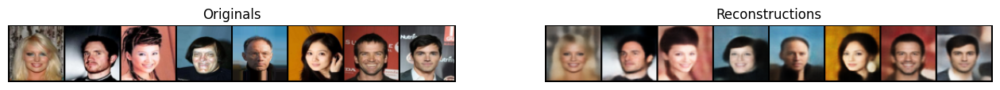

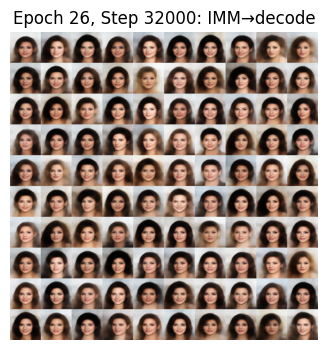

[Epoch 26/80  Step 32200]  Reconstruction=0.01795  MMD=0.08405 IMM=0.04593
[Epoch 26/80  Step 32400]  Reconstruction=0.01790  MMD=0.08047 IMM=0.05127
[Epoch 26/80  Step 32600]  Reconstruction=0.01705  MMD=0.03887 IMM=0.10169
[Epoch 26/80  Step 32800]  Reconstruction=0.01656  MMD=0.04587 IMM=0.05479
[Epoch 26/80  Step 33000]  Reconstruction=0.01730  MMD=0.21116 IMM=0.08290


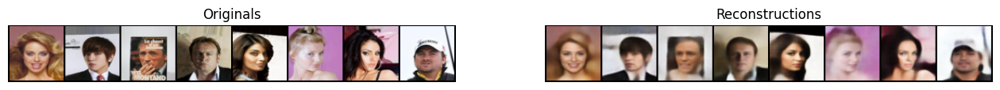

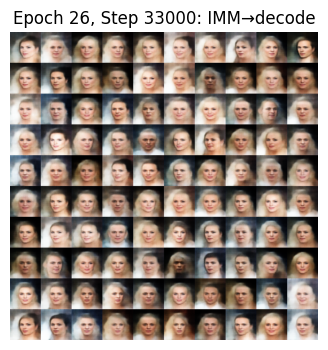

[Epoch 27/80  Step 33200]  Reconstruction=0.01813  MMD=0.02894 IMM=0.09367
[Epoch 27/80  Step 33400]  Reconstruction=0.01632  MMD=0.02530 IMM=0.11475
[Epoch 27/80  Step 33600]  Reconstruction=0.01635  MMD=0.04062 IMM=0.04343
[Epoch 27/80  Step 33800]  Reconstruction=0.01872  MMD=0.22859 IMM=0.01197
[Epoch 27/80  Step 34000]  Reconstruction=0.01649  MMD=0.05477 IMM=0.16468


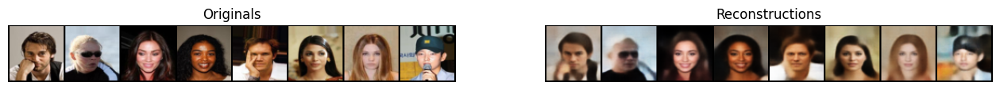

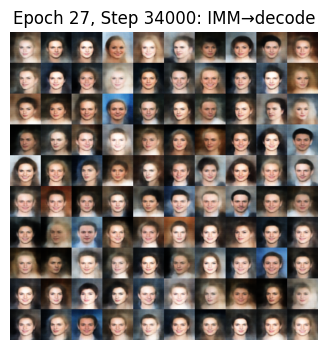

[Epoch 27/80  Step 34200]  Reconstruction=0.01682  MMD=0.03309 IMM=0.03244
[Epoch 28/80  Step 34400]  Reconstruction=0.01708  MMD=0.03973 IMM=0.08023
[Epoch 28/80  Step 34600]  Reconstruction=0.01738  MMD=0.02244 IMM=0.01677
[Epoch 28/80  Step 34800]  Reconstruction=0.01771  MMD=0.05351 IMM=0.13913
[Epoch 28/80  Step 35000]  Reconstruction=0.01644  MMD=0.06216 IMM=0.11605


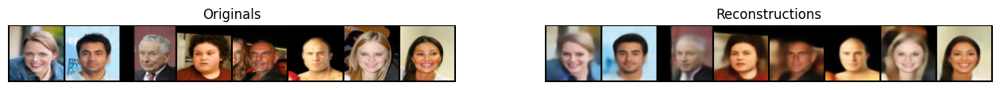

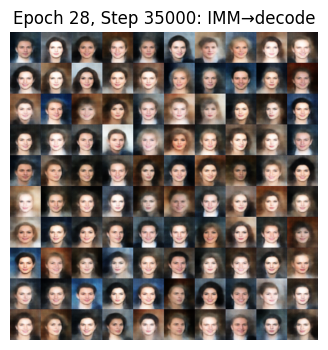

[Epoch 28/80  Step 35200]  Reconstruction=0.01845  MMD=0.03358 IMM=0.03245
[Epoch 28/80  Step 35400]  Reconstruction=0.01868  MMD=0.03665 IMM=0.01964
[Epoch 29/80  Step 35600]  Reconstruction=0.01792  MMD=0.02041 IMM=0.02455
[Epoch 29/80  Step 35800]  Reconstruction=0.01759  MMD=0.02407 IMM=0.06752
[Epoch 29/80  Step 36000]  Reconstruction=0.01904  MMD=0.01925 IMM=0.01025


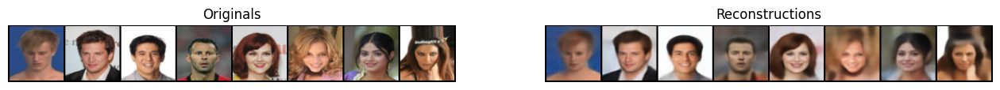

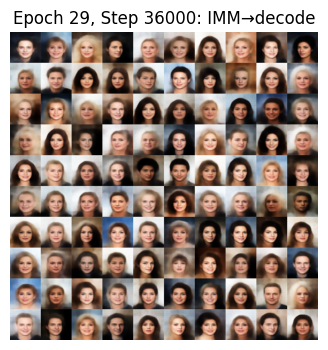

[Epoch 29/80  Step 36200]  Reconstruction=0.01780  MMD=0.02267 IMM=0.03253
[Epoch 29/80  Step 36400]  Reconstruction=0.01825  MMD=0.08214 IMM=0.03222
[Epoch 29/80  Step 36600]  Reconstruction=0.01707  MMD=0.02279 IMM=0.04972
[Epoch 29/80  Step 36800]  Reconstruction=0.01974  MMD=0.02939 IMM=0.00207
[Epoch 30/80  Step 37000]  Reconstruction=0.01727  MMD=0.02228 IMM=0.02598


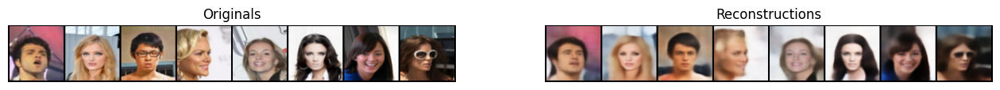

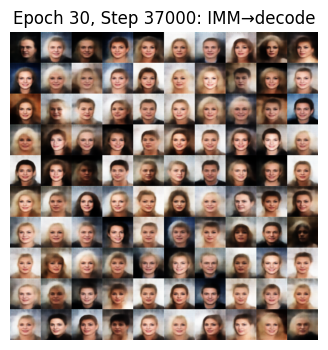

[Epoch 30/80  Step 37200]  Reconstruction=0.01778  MMD=0.02761 IMM=0.06658
[Epoch 30/80  Step 37400]  Reconstruction=0.01765  MMD=0.01911 IMM=0.04137
[Epoch 30/80  Step 37600]  Reconstruction=0.01759  MMD=0.24956 IMM=0.07354
[Epoch 30/80  Step 37800]  Reconstruction=0.01669  MMD=0.01908 IMM=0.04991
[Epoch 30/80  Step 38000]  Reconstruction=0.01683  MMD=0.01771 IMM=0.04036


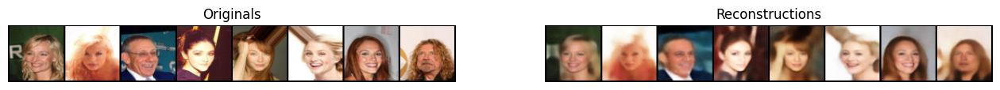

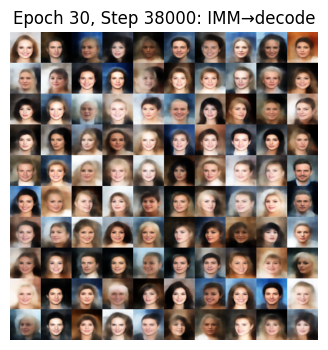

[Epoch 31/80  Step 38200]  Reconstruction=0.01773  MMD=0.02149 IMM=0.02262
[Epoch 31/80  Step 38400]  Reconstruction=0.01866  MMD=0.02182 IMM=0.04892
[Epoch 31/80  Step 38600]  Reconstruction=0.01732  MMD=0.09881 IMM=0.08805
[Epoch 31/80  Step 38800]  Reconstruction=0.01793  MMD=0.01880 IMM=0.10622
[Epoch 31/80  Step 39000]  Reconstruction=0.01942  MMD=0.01792 IMM=0.13610


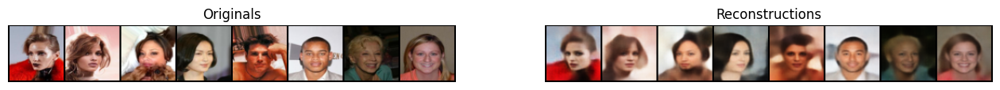

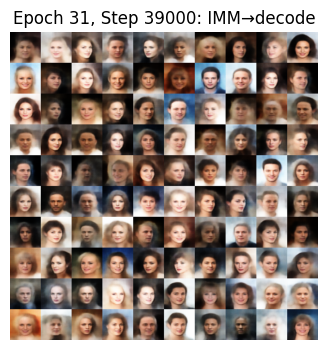

[Epoch 31/80  Step 39200]  Reconstruction=0.01724  MMD=0.01786 IMM=0.06427
[Epoch 31/80  Step 39400]  Reconstruction=0.01842  MMD=0.04300 IMM=0.03089
[Epoch 32/80  Step 39600]  Reconstruction=0.01815  MMD=0.02415 IMM=0.12048
[Epoch 32/80  Step 39800]  Reconstruction=0.01662  MMD=0.12410 IMM=0.02728
[Epoch 32/80  Step 40000]  Reconstruction=0.01733  MMD=0.03605 IMM=0.03612


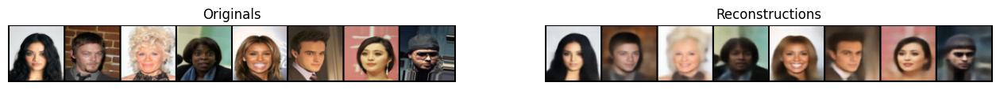

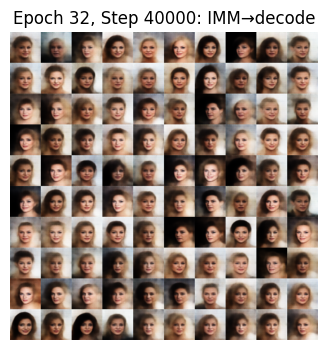

[Epoch 32/80  Step 40200]  Reconstruction=0.01778  MMD=0.02802 IMM=0.01036
[Epoch 32/80  Step 40400]  Reconstruction=0.01608  MMD=0.03101 IMM=0.12402
[Epoch 32/80  Step 40600]  Reconstruction=0.01662  MMD=0.05022 IMM=0.08180
[Epoch 33/80  Step 40800]  Reconstruction=0.01631  MMD=0.01958 IMM=0.01216
[Epoch 33/80  Step 41000]  Reconstruction=0.01804  MMD=0.01706 IMM=0.10528


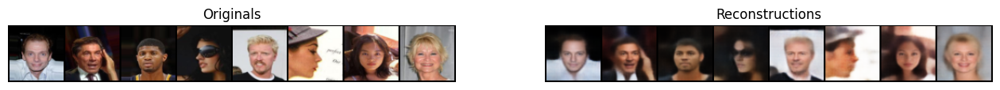

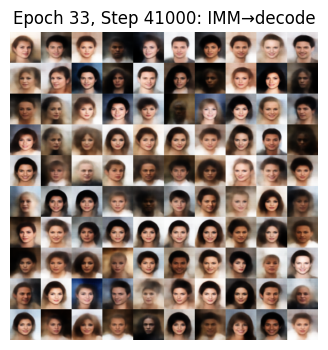

[Epoch 33/80  Step 41200]  Reconstruction=0.01546  MMD=0.02559 IMM=0.06232
[Epoch 33/80  Step 41400]  Reconstruction=0.01617  MMD=0.01947 IMM=0.06839
[Epoch 33/80  Step 41600]  Reconstruction=0.01779  MMD=0.02262 IMM=0.06509
[Epoch 33/80  Step 41800]  Reconstruction=0.01801  MMD=0.02729 IMM=0.06110
[Epoch 34/80  Step 42000]  Reconstruction=0.01580  MMD=0.03012 IMM=0.02567


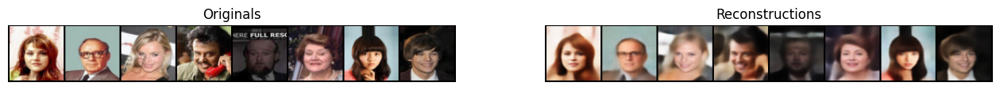

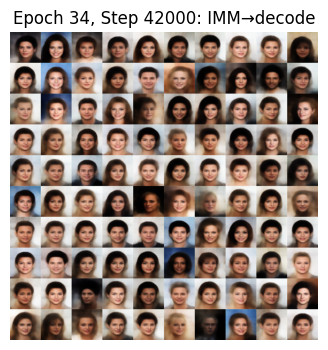

[Epoch 34/80  Step 42200]  Reconstruction=0.01831  MMD=0.01780 IMM=0.05559
[Epoch 34/80  Step 42400]  Reconstruction=0.01729  MMD=0.01785 IMM=0.02023
[Epoch 34/80  Step 42600]  Reconstruction=0.01703  MMD=0.04254 IMM=0.01164
[Epoch 34/80  Step 42800]  Reconstruction=0.01802  MMD=0.01905 IMM=0.04727
[Epoch 34/80  Step 43000]  Reconstruction=0.01699  MMD=0.02417 IMM=0.04826


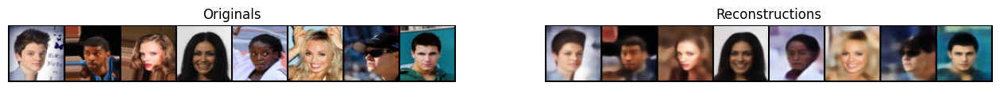

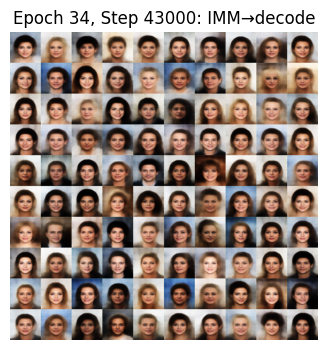

[Epoch 34/80  Step 43200]  Reconstruction=0.01532  MMD=0.02992 IMM=0.06789
[Epoch 35/80  Step 43400]  Reconstruction=0.01802  MMD=0.01990 IMM=0.00697
[Epoch 35/80  Step 43600]  Reconstruction=0.01860  MMD=0.04095 IMM=0.07492
[Epoch 35/80  Step 43800]  Reconstruction=0.01753  MMD=0.03490 IMM=0.08092
[Epoch 35/80  Step 44000]  Reconstruction=0.01653  MMD=0.01680 IMM=0.05315


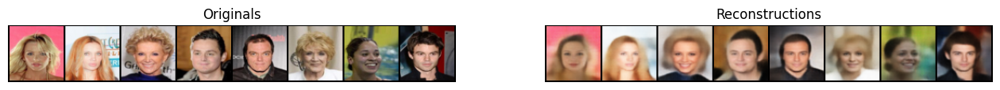

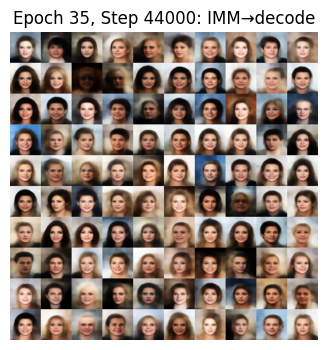

[Epoch 35/80  Step 44200]  Reconstruction=0.01749  MMD=0.02236 IMM=0.04256
[Epoch 35/80  Step 44400]  Reconstruction=0.01690  MMD=0.01754 IMM=0.10807
[Epoch 36/80  Step 44600]  Reconstruction=0.01704  MMD=0.01825 IMM=0.04395
[Epoch 36/80  Step 44800]  Reconstruction=0.01699  MMD=0.01635 IMM=0.03229
[Epoch 36/80  Step 45000]  Reconstruction=0.01591  MMD=0.01719 IMM=0.18738


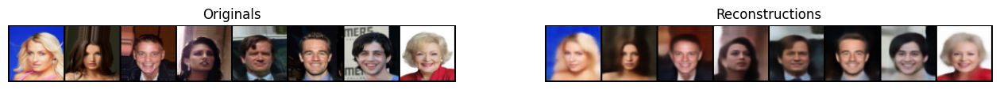

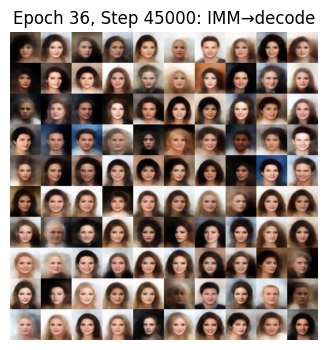

[Epoch 36/80  Step 45200]  Reconstruction=0.01697  MMD=0.01730 IMM=0.08178
[Epoch 36/80  Step 45400]  Reconstruction=0.01736  MMD=0.02371 IMM=0.03384
[Epoch 36/80  Step 45600]  Reconstruction=0.01657  MMD=0.02060 IMM=0.11813
[Epoch 37/80  Step 45800]  Reconstruction=0.01632  MMD=0.02866 IMM=0.01761
[Epoch 37/80  Step 46000]  Reconstruction=0.01645  MMD=0.01783 IMM=0.03088


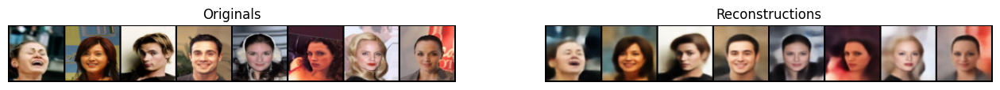

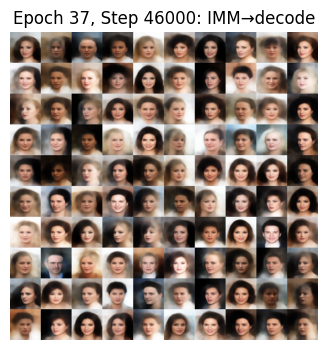

[Epoch 37/80  Step 46200]  Reconstruction=0.01644  MMD=0.01725 IMM=0.07760
[Epoch 37/80  Step 46400]  Reconstruction=0.01802  MMD=0.01605 IMM=0.09878
[Epoch 37/80  Step 46600]  Reconstruction=0.01792  MMD=0.01583 IMM=0.09622
[Epoch 37/80  Step 46800]  Reconstruction=0.01759  MMD=0.01662 IMM=0.07985
[Epoch 37/80  Step 47000]  Reconstruction=0.01653  MMD=0.01649 IMM=0.02043


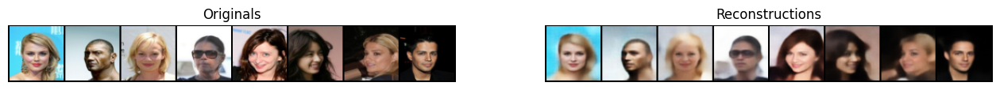

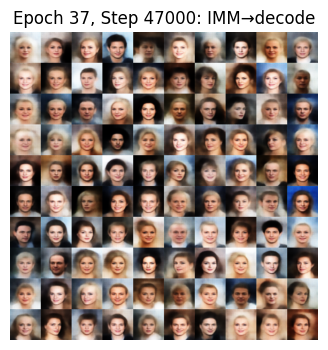

[Epoch 38/80  Step 47200]  Reconstruction=0.01788  MMD=0.01719 IMM=0.07541
[Epoch 38/80  Step 47400]  Reconstruction=0.01737  MMD=0.02164 IMM=0.00658
[Epoch 38/80  Step 47600]  Reconstruction=0.01604  MMD=0.08844 IMM=0.03764
[Epoch 38/80  Step 47800]  Reconstruction=0.01823  MMD=0.01579 IMM=0.08386
[Epoch 38/80  Step 48000]  Reconstruction=0.01651  MMD=0.01742 IMM=0.09832


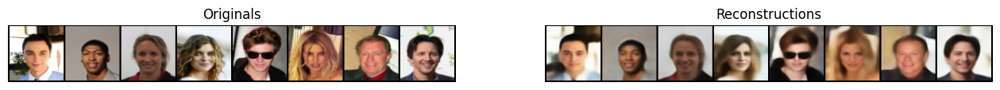

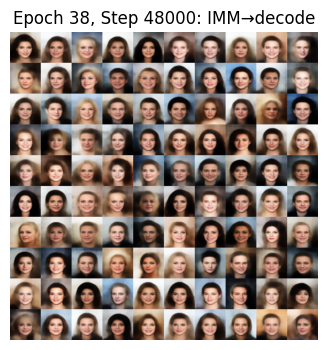

[Epoch 38/80  Step 48200]  Reconstruction=0.01783  MMD=0.01598 IMM=0.01384
[Epoch 39/80  Step 48400]  Reconstruction=0.01684  MMD=0.01651 IMM=0.01772
[Epoch 39/80  Step 48600]  Reconstruction=0.01781  MMD=0.01591 IMM=0.01307
[Epoch 39/80  Step 48800]  Reconstruction=0.01683  MMD=0.01614 IMM=0.04328
[Epoch 39/80  Step 49000]  Reconstruction=0.01590  MMD=0.01596 IMM=0.01497


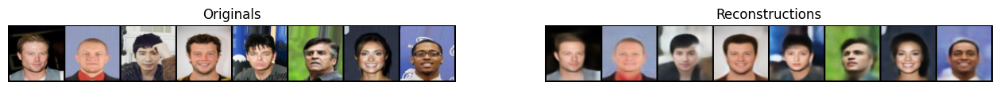

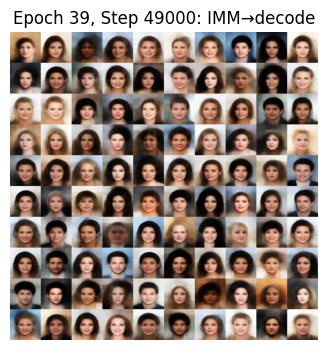

[Epoch 39/80  Step 49200]  Reconstruction=0.01641  MMD=0.01588 IMM=0.09496
[Epoch 39/80  Step 49400]  Reconstruction=0.01607  MMD=0.01594 IMM=0.05703
[Epoch 40/80  Step 49600]  Reconstruction=0.01682  MMD=0.01599 IMM=0.10098
[Epoch 40/80  Step 49800]  Reconstruction=0.01679  MMD=0.02049 IMM=0.10340
[Epoch 40/80  Step 50000]  Reconstruction=0.01726  MMD=0.01657 IMM=0.01502


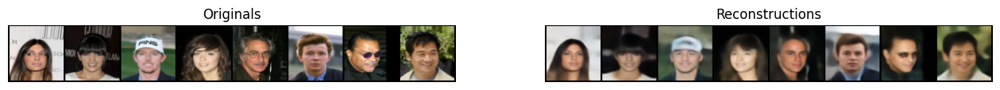

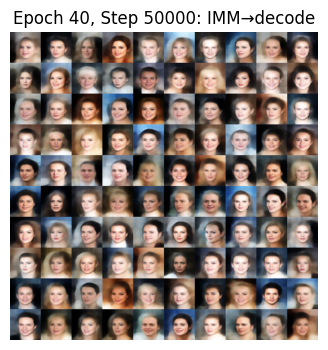

[Epoch 40/80  Step 50200]  Reconstruction=0.01539  MMD=0.01701 IMM=0.02003
[Epoch 40/80  Step 50400]  Reconstruction=0.01642  MMD=0.02066 IMM=0.02035
[Epoch 40/80  Step 50600]  Reconstruction=0.01802  MMD=0.01669 IMM=0.15136
[Epoch 40/80  Step 50800]  Reconstruction=0.01738  MMD=0.01976 IMM=0.05502
[Epoch 41/80  Step 51000]  Reconstruction=0.01725  MMD=0.02055 IMM=0.02830


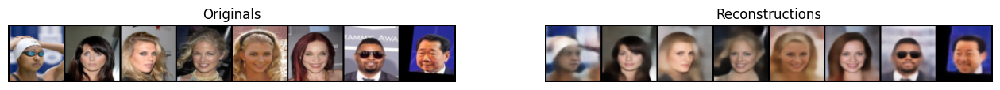

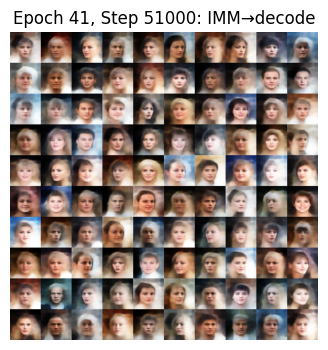

[Epoch 41/80  Step 51200]  Reconstruction=0.01646  MMD=0.01576 IMM=0.07836
[Epoch 41/80  Step 51400]  Reconstruction=0.01654  MMD=0.01597 IMM=0.02613
[Epoch 41/80  Step 51600]  Reconstruction=0.01727  MMD=0.01593 IMM=0.05373
[Epoch 41/80  Step 51800]  Reconstruction=0.01687  MMD=0.01739 IMM=0.09862
[Epoch 41/80  Step 52000]  Reconstruction=0.01711  MMD=0.01648 IMM=0.03094


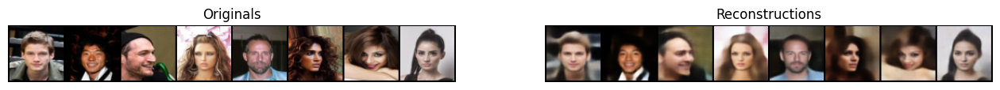

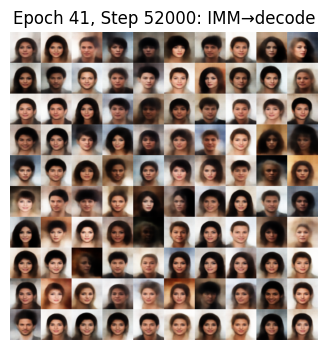

[Epoch 42/80  Step 52200]  Reconstruction=0.01667  MMD=0.01816 IMM=0.06330
[Epoch 42/80  Step 52400]  Reconstruction=0.01646  MMD=0.02858 IMM=0.11392
[Epoch 42/80  Step 52600]  Reconstruction=0.01850  MMD=0.02778 IMM=0.12216
[Epoch 42/80  Step 52800]  Reconstruction=0.01671  MMD=0.01591 IMM=0.08459
[Epoch 42/80  Step 53000]  Reconstruction=0.01679  MMD=0.01607 IMM=0.06564


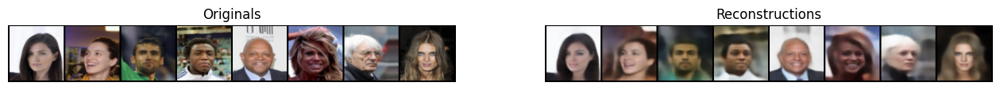

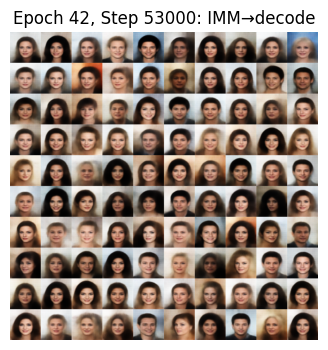

[Epoch 42/80  Step 53200]  Reconstruction=0.01561  MMD=0.02173 IMM=0.16436
[Epoch 43/80  Step 53400]  Reconstruction=0.01532  MMD=0.01592 IMM=0.08058
[Epoch 43/80  Step 53600]  Reconstruction=0.01638  MMD=0.01571 IMM=0.09246
[Epoch 43/80  Step 53800]  Reconstruction=0.01735  MMD=0.01632 IMM=0.07701
[Epoch 43/80  Step 54000]  Reconstruction=0.01680  MMD=0.01565 IMM=0.14842


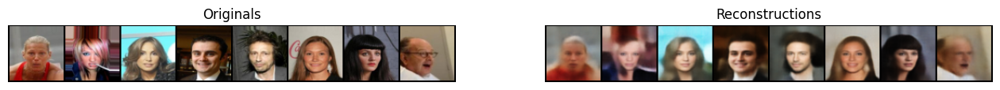

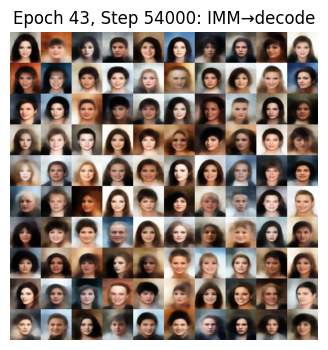

[Epoch 43/80  Step 54200]  Reconstruction=0.01706  MMD=0.01628 IMM=0.06234
[Epoch 43/80  Step 54400]  Reconstruction=0.01620  MMD=0.01576 IMM=0.02882
[Epoch 43/80  Step 54600]  Reconstruction=0.01697  MMD=0.01589 IMM=0.02743
[Epoch 44/80  Step 54800]  Reconstruction=0.01629  MMD=0.01616 IMM=0.18944
[Epoch 44/80  Step 55000]  Reconstruction=0.01695  MMD=0.01597 IMM=0.10449


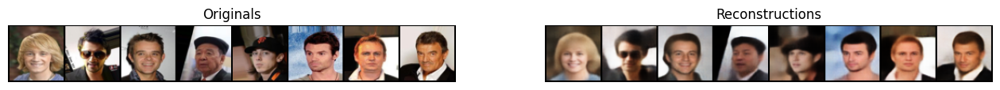

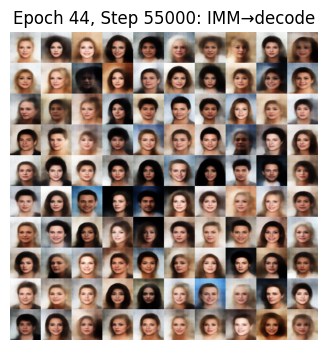

[Epoch 44/80  Step 55200]  Reconstruction=0.01631  MMD=0.02011 IMM=0.02981
[Epoch 44/80  Step 55400]  Reconstruction=0.01629  MMD=0.01878 IMM=0.02749
[Epoch 44/80  Step 55600]  Reconstruction=0.01653  MMD=0.01619 IMM=0.11046
[Epoch 44/80  Step 55800]  Reconstruction=0.01686  MMD=0.03595 IMM=0.03533
[Epoch 45/80  Step 56000]  Reconstruction=0.01647  MMD=0.01806 IMM=0.08668


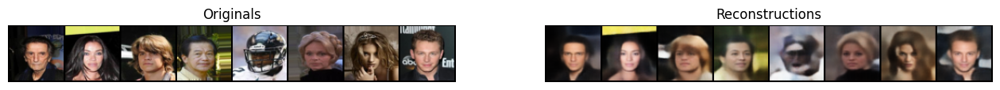

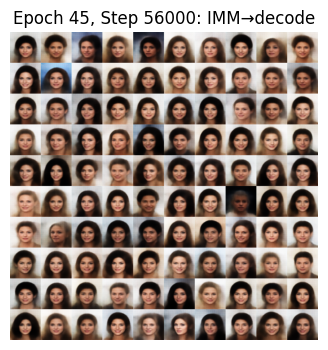

[Epoch 45/80  Step 56200]  Reconstruction=0.01596  MMD=0.01571 IMM=0.10197
[Epoch 45/80  Step 56400]  Reconstruction=0.01597  MMD=0.01673 IMM=0.13483
[Epoch 45/80  Step 56600]  Reconstruction=0.01459  MMD=0.01565 IMM=0.04062
[Epoch 45/80  Step 56800]  Reconstruction=0.01668  MMD=0.01617 IMM=0.05395
[Epoch 45/80  Step 57000]  Reconstruction=0.01605  MMD=0.10501 IMM=0.05203


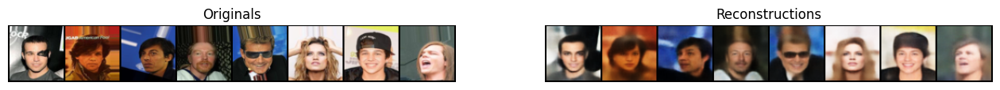

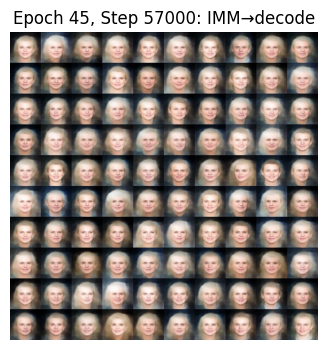

[Epoch 46/80  Step 57200]  Reconstruction=0.01721  MMD=0.01572 IMM=0.06840
[Epoch 46/80  Step 57400]  Reconstruction=0.01693  MMD=0.01627 IMM=0.15690
[Epoch 46/80  Step 57600]  Reconstruction=0.01703  MMD=0.01568 IMM=0.09793
[Epoch 46/80  Step 57800]  Reconstruction=0.01577  MMD=0.01575 IMM=0.05614
[Epoch 46/80  Step 58000]  Reconstruction=0.01744  MMD=0.02207 IMM=0.17856


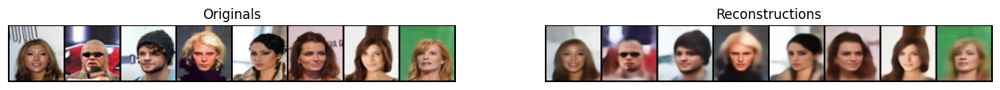

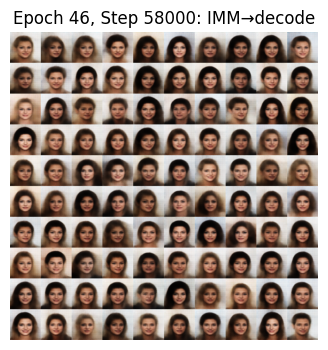

[Epoch 46/80  Step 58200]  Reconstruction=0.01597  MMD=0.01658 IMM=0.06839
[Epoch 46/80  Step 58400]  Reconstruction=0.01604  MMD=0.01573 IMM=0.12633
[Epoch 47/80  Step 58600]  Reconstruction=0.01588  MMD=0.01691 IMM=0.14682
[Epoch 47/80  Step 58800]  Reconstruction=0.01611  MMD=0.01567 IMM=0.06628
[Epoch 47/80  Step 59000]  Reconstruction=0.01641  MMD=0.01567 IMM=0.08438


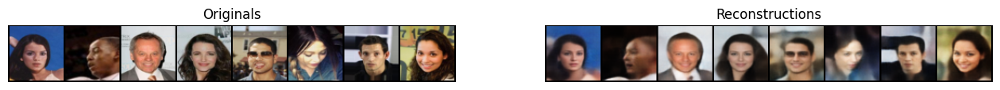

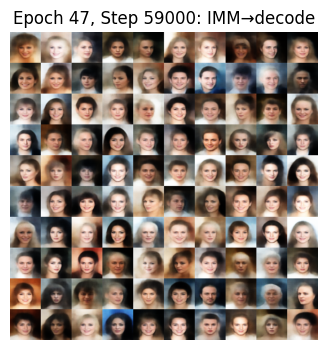

[Epoch 47/80  Step 59200]  Reconstruction=0.01548  MMD=0.01599 IMM=0.15113
[Epoch 47/80  Step 59400]  Reconstruction=0.01707  MMD=0.01568 IMM=0.12296
[Epoch 47/80  Step 59600]  Reconstruction=0.01762  MMD=0.01564 IMM=0.04515
[Epoch 48/80  Step 59800]  Reconstruction=0.01713  MMD=0.01563 IMM=0.06358
[Epoch 48/80  Step 60000]  Reconstruction=0.01686  MMD=0.01564 IMM=0.07475


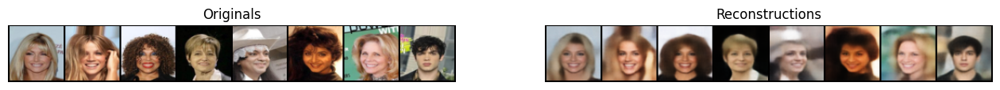

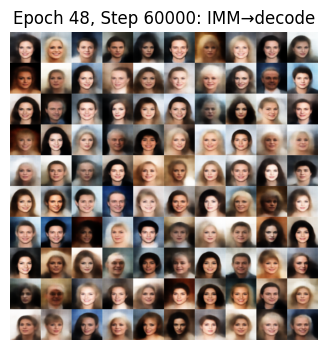

[Epoch 48/80  Step 60200]  Reconstruction=0.01691  MMD=0.01568 IMM=0.03049
[Epoch 48/80  Step 60400]  Reconstruction=0.01583  MMD=0.01563 IMM=0.10528
[Epoch 48/80  Step 60600]  Reconstruction=0.01606  MMD=0.01632 IMM=0.05234
[Epoch 48/80  Step 60800]  Reconstruction=0.01656  MMD=0.01618 IMM=0.08027
[Epoch 48/80  Step 61000]  Reconstruction=0.01513  MMD=0.01565 IMM=0.06359


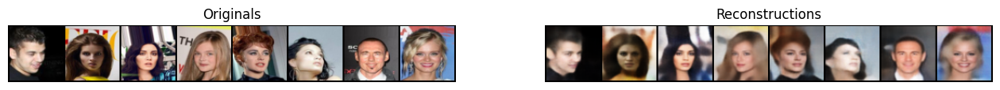

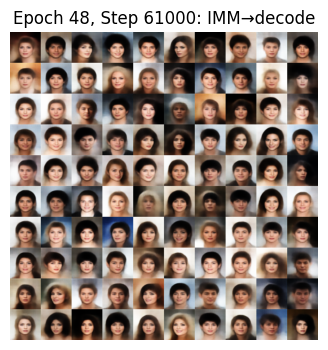

[Epoch 49/80  Step 61200]  Reconstruction=0.01720  MMD=0.01566 IMM=0.06788
[Epoch 49/80  Step 61400]  Reconstruction=0.01667  MMD=0.03821 IMM=0.00155
[Epoch 49/80  Step 61600]  Reconstruction=0.01819  MMD=0.01628 IMM=0.10103
[Epoch 49/80  Step 61800]  Reconstruction=0.01736  MMD=0.02762 IMM=0.08688
[Epoch 49/80  Step 62000]  Reconstruction=0.01645  MMD=0.01563 IMM=0.14901


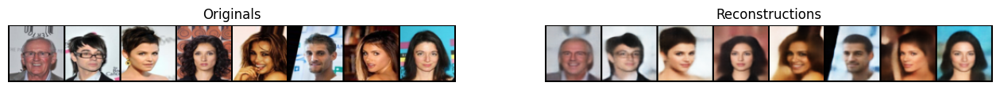

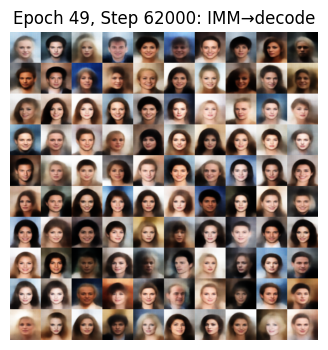

[Epoch 49/80  Step 62200]  Reconstruction=0.01555  MMD=0.01564 IMM=0.08503
[Epoch 50/80  Step 62400]  Reconstruction=0.01613  MMD=0.01563 IMM=0.04701
[Epoch 50/80  Step 62600]  Reconstruction=0.01583  MMD=0.01564 IMM=0.03833
[Epoch 50/80  Step 62800]  Reconstruction=0.01649  MMD=0.01566 IMM=0.09739
[Epoch 50/80  Step 63000]  Reconstruction=0.01600  MMD=0.01563 IMM=0.11682


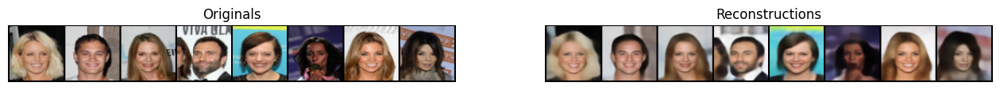

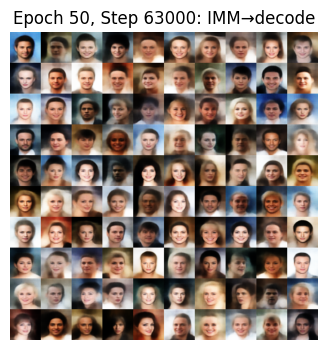

[Epoch 50/80  Step 63200]  Reconstruction=0.01730  MMD=0.01568 IMM=0.06622
[Epoch 50/80  Step 63400]  Reconstruction=0.01593  MMD=0.01569 IMM=0.10670
[Epoch 51/80  Step 63600]  Reconstruction=0.01590  MMD=0.01568 IMM=0.11843
[Epoch 51/80  Step 63800]  Reconstruction=0.01654  MMD=0.01564 IMM=0.08779
[Epoch 51/80  Step 64000]  Reconstruction=0.01663  MMD=0.01563 IMM=0.08320


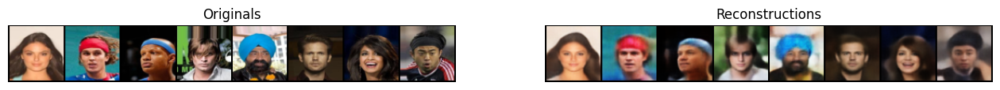

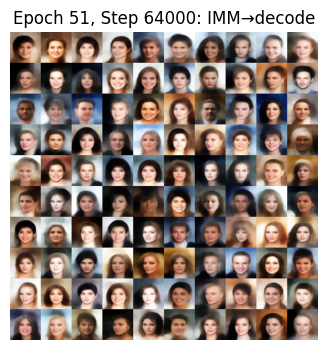

[Epoch 51/80  Step 64200]  Reconstruction=0.01581  MMD=0.01672 IMM=0.01392
[Epoch 51/80  Step 64400]  Reconstruction=0.01640  MMD=0.01563 IMM=0.10007
[Epoch 51/80  Step 64600]  Reconstruction=0.01621  MMD=0.01567 IMM=0.04731
[Epoch 51/80  Step 64800]  Reconstruction=0.01757  MMD=0.01564 IMM=0.02841
[Epoch 52/80  Step 65000]  Reconstruction=0.01602  MMD=0.01563 IMM=0.09926


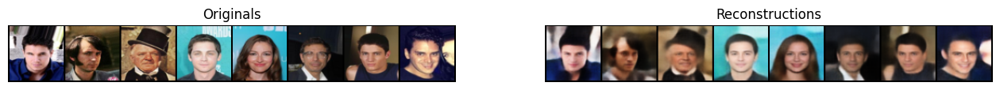

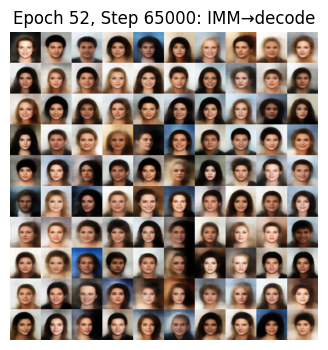

[Epoch 52/80  Step 65200]  Reconstruction=0.01610  MMD=0.01840 IMM=0.06220
[Epoch 52/80  Step 65400]  Reconstruction=0.01649  MMD=0.01594 IMM=0.01626
[Epoch 52/80  Step 65600]  Reconstruction=0.01590  MMD=0.01568 IMM=0.09352
[Epoch 52/80  Step 65800]  Reconstruction=0.01528  MMD=0.01563 IMM=0.04526
[Epoch 52/80  Step 66000]  Reconstruction=0.01777  MMD=0.01563 IMM=0.04399


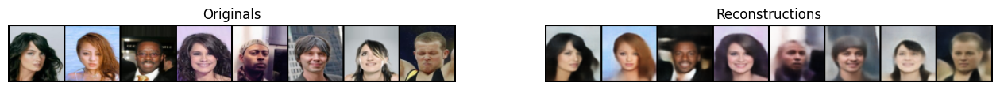

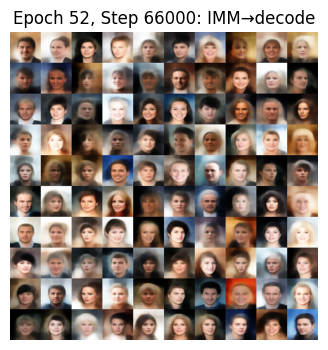

[Epoch 53/80  Step 66200]  Reconstruction=0.01688  MMD=0.01564 IMM=0.01766
[Epoch 53/80  Step 66400]  Reconstruction=0.01597  MMD=0.01564 IMM=0.04069
[Epoch 53/80  Step 66600]  Reconstruction=0.01567  MMD=0.01563 IMM=0.01668
[Epoch 53/80  Step 66800]  Reconstruction=0.01671  MMD=0.01596 IMM=0.04166
[Epoch 53/80  Step 67000]  Reconstruction=0.01590  MMD=0.01563 IMM=0.07173


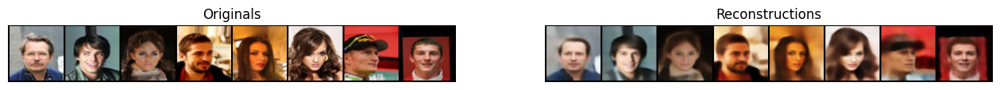

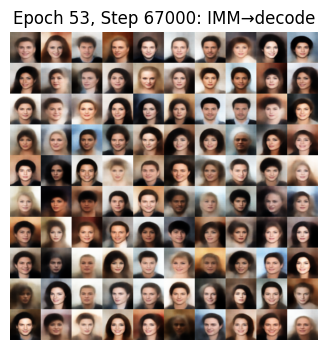

[Epoch 53/80  Step 67200]  Reconstruction=0.01644  MMD=0.01563 IMM=0.04475
[Epoch 54/80  Step 67400]  Reconstruction=0.01501  MMD=0.01564 IMM=0.02132
[Epoch 54/80  Step 67600]  Reconstruction=0.01622  MMD=0.01567 IMM=0.03589
[Epoch 54/80  Step 67800]  Reconstruction=0.01560  MMD=0.01622 IMM=0.09315
[Epoch 54/80  Step 68000]  Reconstruction=0.01573  MMD=0.01563 IMM=0.13337


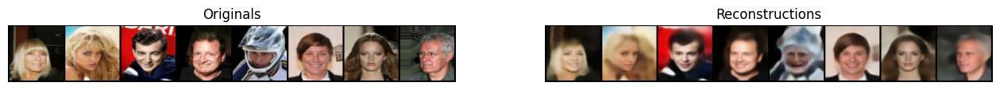

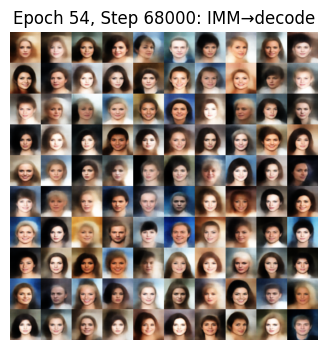

[Epoch 54/80  Step 68200]  Reconstruction=0.01703  MMD=0.01566 IMM=0.01739
[Epoch 54/80  Step 68400]  Reconstruction=0.01642  MMD=0.01567 IMM=0.12034
[Epoch 54/80  Step 68600]  Reconstruction=0.01608  MMD=0.01563 IMM=0.13853
[Epoch 55/80  Step 68800]  Reconstruction=0.01682  MMD=0.01567 IMM=0.06814
[Epoch 55/80  Step 69000]  Reconstruction=0.01618  MMD=0.01563 IMM=0.09340


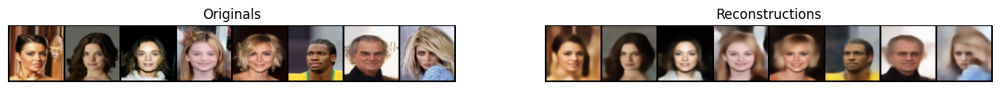

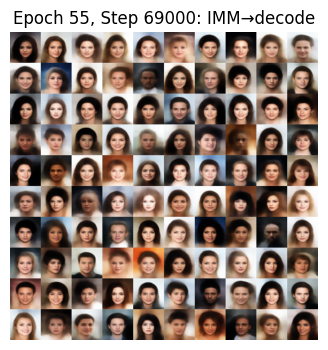

[Epoch 55/80  Step 69200]  Reconstruction=0.01597  MMD=0.01570 IMM=0.08520
[Epoch 55/80  Step 69400]  Reconstruction=0.01711  MMD=0.01563 IMM=0.04803
[Epoch 55/80  Step 69600]  Reconstruction=0.01724  MMD=0.01580 IMM=0.03703
[Epoch 55/80  Step 69800]  Reconstruction=0.01668  MMD=0.01563 IMM=0.09347
[Epoch 56/80  Step 70000]  Reconstruction=0.01664  MMD=0.01725 IMM=0.07616


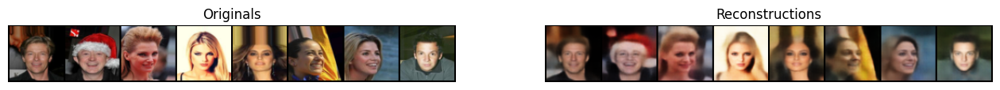

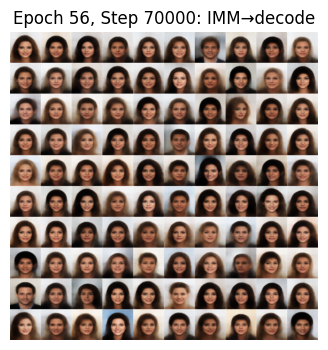

[Epoch 56/80  Step 70200]  Reconstruction=0.01658  MMD=0.01565 IMM=0.04831
[Epoch 56/80  Step 70400]  Reconstruction=0.01599  MMD=0.01813 IMM=0.17923
[Epoch 56/80  Step 70600]  Reconstruction=0.01718  MMD=0.01568 IMM=0.08855
[Epoch 56/80  Step 70800]  Reconstruction=0.01710  MMD=0.01565 IMM=0.06226
[Epoch 56/80  Step 71000]  Reconstruction=0.01742  MMD=0.01570 IMM=0.08145


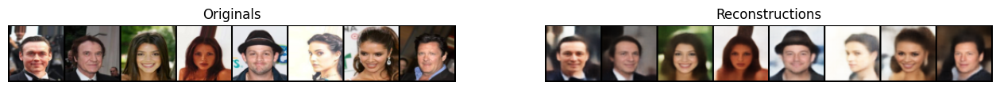

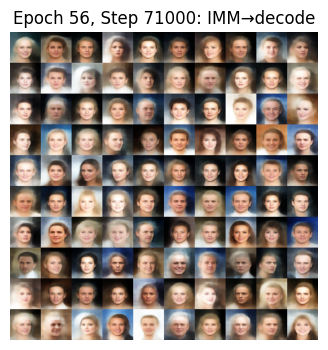

[Epoch 57/80  Step 71200]  Reconstruction=0.01761  MMD=0.01703 IMM=0.14315
[Epoch 57/80  Step 71400]  Reconstruction=0.01715  MMD=0.01563 IMM=0.07780
[Epoch 57/80  Step 71600]  Reconstruction=0.01530  MMD=0.01563 IMM=0.04246
[Epoch 57/80  Step 71800]  Reconstruction=0.01636  MMD=0.01563 IMM=0.04960
[Epoch 57/80  Step 72000]  Reconstruction=0.01593  MMD=0.01563 IMM=0.10515


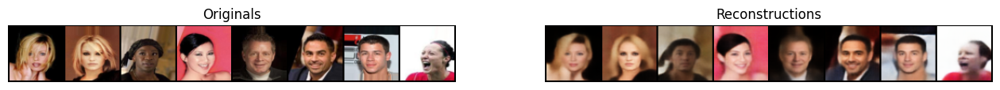

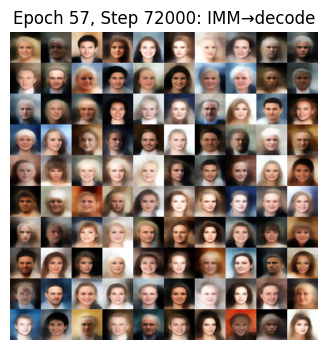

[Epoch 57/80  Step 72200]  Reconstruction=0.01762  MMD=0.01563 IMM=0.07097
[Epoch 57/80  Step 72400]  Reconstruction=0.01656  MMD=0.01563 IMM=0.02890
[Epoch 58/80  Step 72600]  Reconstruction=0.01780  MMD=0.01564 IMM=0.07106
[Epoch 58/80  Step 72800]  Reconstruction=0.01507  MMD=0.01563 IMM=0.03668
[Epoch 58/80  Step 73000]  Reconstruction=0.01577  MMD=0.01563 IMM=0.05576


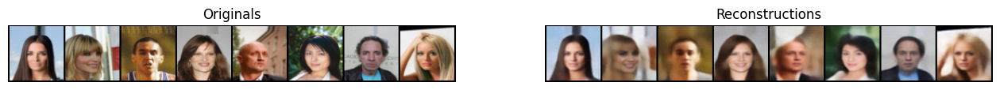

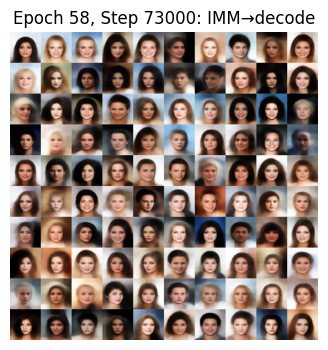

[Epoch 58/80  Step 73200]  Reconstruction=0.01620  MMD=0.01756 IMM=0.00958
[Epoch 58/80  Step 73400]  Reconstruction=0.01589  MMD=0.01564 IMM=0.02843
[Epoch 58/80  Step 73600]  Reconstruction=0.01657  MMD=0.01667 IMM=0.12428
[Epoch 59/80  Step 73800]  Reconstruction=0.01693  MMD=0.01563 IMM=0.21883
[Epoch 59/80  Step 74000]  Reconstruction=0.01672  MMD=0.01563 IMM=0.13596


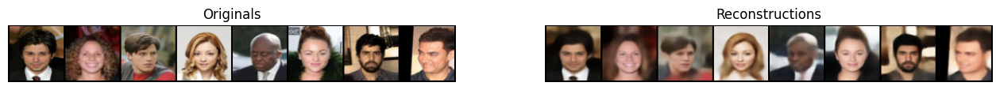

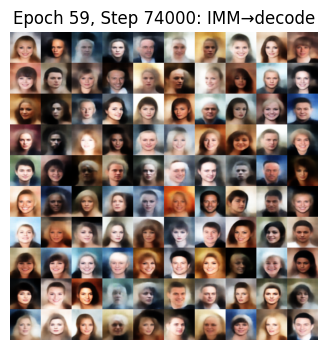

[Epoch 59/80  Step 74200]  Reconstruction=0.01571  MMD=0.01563 IMM=0.08694
[Epoch 59/80  Step 74400]  Reconstruction=0.01717  MMD=0.01563 IMM=0.06619
[Epoch 59/80  Step 74600]  Reconstruction=0.01691  MMD=0.01836 IMM=0.11456
[Epoch 59/80  Step 74800]  Reconstruction=0.01448  MMD=0.03097 IMM=0.09915
[Epoch 60/80  Step 75000]  Reconstruction=0.01504  MMD=0.01563 IMM=0.06847


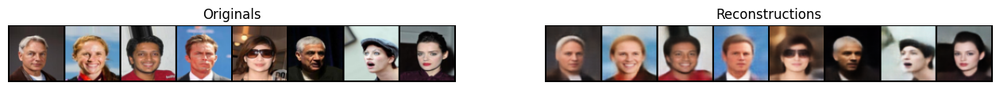

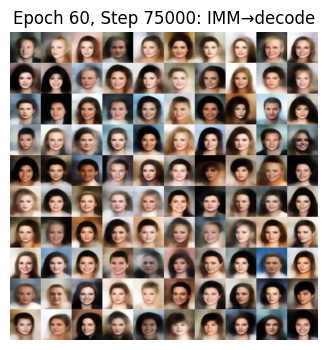

[Epoch 60/80  Step 75200]  Reconstruction=0.01651  MMD=0.01563 IMM=0.02093
[Epoch 60/80  Step 75400]  Reconstruction=0.01672  MMD=0.01563 IMM=0.11841
[Epoch 60/80  Step 75600]  Reconstruction=0.01608  MMD=0.01782 IMM=0.02601
[Epoch 60/80  Step 75800]  Reconstruction=0.01586  MMD=0.01565 IMM=0.04367
[Epoch 60/80  Step 76000]  Reconstruction=0.01580  MMD=0.01563 IMM=0.12604


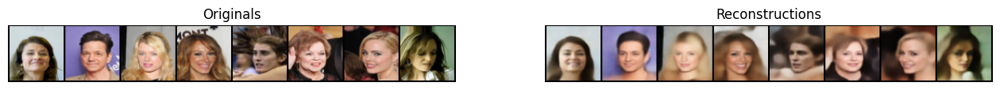

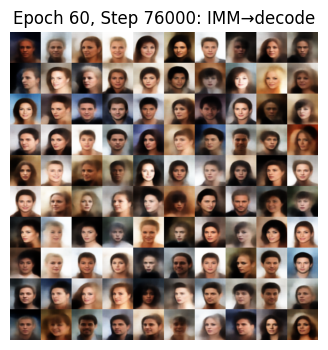

[Epoch 60/80  Step 76200]  Reconstruction=0.01691  MMD=0.01563 IMM=0.04562
[Epoch 61/80  Step 76400]  Reconstruction=0.01518  MMD=0.01564 IMM=0.04123
[Epoch 61/80  Step 76600]  Reconstruction=0.01760  MMD=0.01588 IMM=0.16458
[Epoch 61/80  Step 76800]  Reconstruction=0.01582  MMD=0.01563 IMM=0.03619
[Epoch 61/80  Step 77000]  Reconstruction=0.01771  MMD=0.01563 IMM=0.15349


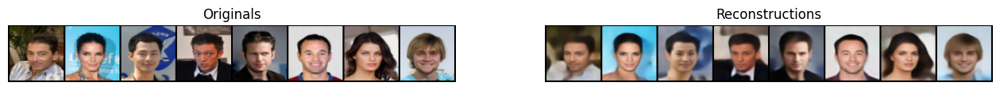

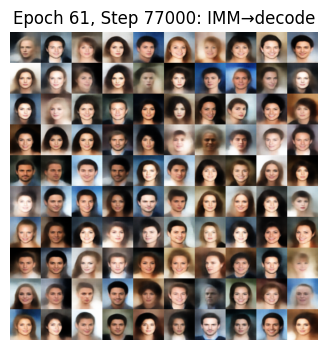

[Epoch 61/80  Step 77200]  Reconstruction=0.01642  MMD=0.01563 IMM=0.06504
[Epoch 61/80  Step 77400]  Reconstruction=0.01514  MMD=0.01563 IMM=0.07917
[Epoch 62/80  Step 77600]  Reconstruction=0.01490  MMD=0.01563 IMM=0.07725
[Epoch 62/80  Step 77800]  Reconstruction=0.01514  MMD=0.01563 IMM=0.08031
[Epoch 62/80  Step 78000]  Reconstruction=0.01548  MMD=0.01563 IMM=0.02392


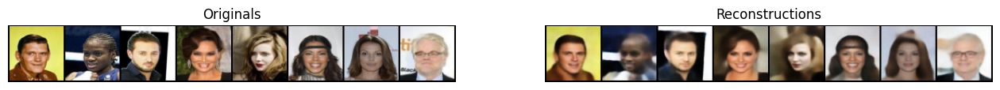

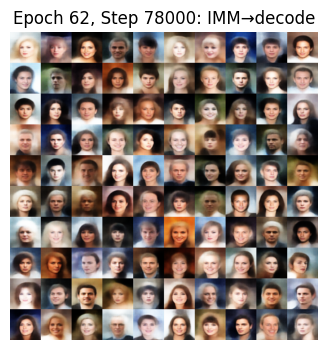

[Epoch 62/80  Step 78200]  Reconstruction=0.01598  MMD=0.01563 IMM=0.07118
[Epoch 62/80  Step 78400]  Reconstruction=0.01575  MMD=0.01563 IMM=0.01654
[Epoch 62/80  Step 78600]  Reconstruction=0.01620  MMD=0.01563 IMM=0.17689
[Epoch 62/80  Step 78800]  Reconstruction=0.01627  MMD=0.01563 IMM=0.11595
[Epoch 63/80  Step 79000]  Reconstruction=0.01708  MMD=0.01563 IMM=0.22082


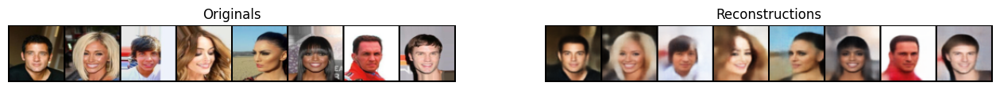

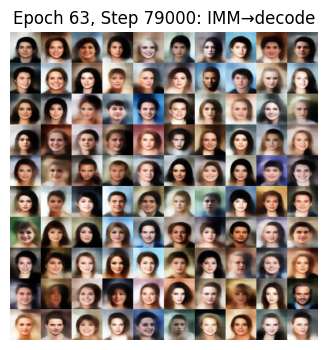

[Epoch 63/80  Step 79200]  Reconstruction=0.01707  MMD=0.01563 IMM=0.07850
[Epoch 63/80  Step 79400]  Reconstruction=0.01511  MMD=0.01563 IMM=0.14100
[Epoch 63/80  Step 79600]  Reconstruction=0.01664  MMD=0.01563 IMM=0.08879
[Epoch 63/80  Step 79800]  Reconstruction=0.01726  MMD=0.01563 IMM=0.04822
[Epoch 63/80  Step 80000]  Reconstruction=0.01671  MMD=0.01563 IMM=0.08179


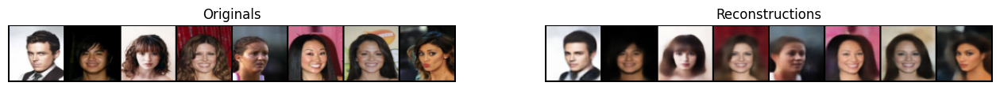

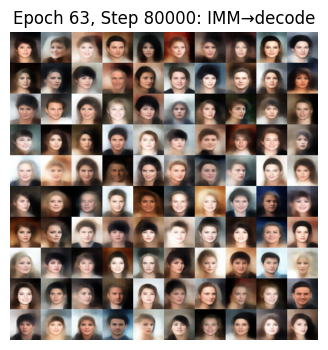

[Epoch 64/80  Step 80200]  Reconstruction=0.01619  MMD=0.01563 IMM=0.06415
[Epoch 64/80  Step 80400]  Reconstruction=0.01627  MMD=0.01564 IMM=0.13003
[Epoch 64/80  Step 80600]  Reconstruction=0.01628  MMD=0.01563 IMM=0.15066
[Epoch 64/80  Step 80800]  Reconstruction=0.01539  MMD=0.01563 IMM=0.09905
[Epoch 64/80  Step 81000]  Reconstruction=0.01573  MMD=0.01563 IMM=0.06427


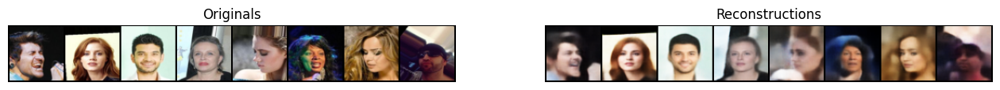

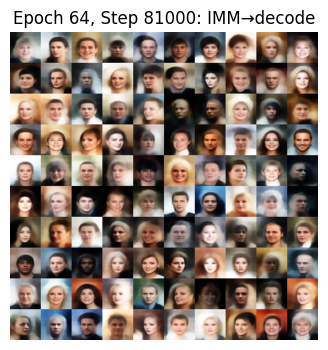

[Epoch 64/80  Step 81200]  Reconstruction=0.01622  MMD=0.01563 IMM=0.04357
[Epoch 65/80  Step 81400]  Reconstruction=0.01642  MMD=0.01631 IMM=0.11793
[Epoch 65/80  Step 81600]  Reconstruction=0.01588  MMD=0.01563 IMM=0.14352
[Epoch 65/80  Step 81800]  Reconstruction=0.01686  MMD=0.01563 IMM=0.09835
[Epoch 65/80  Step 82000]  Reconstruction=0.01503  MMD=0.01563 IMM=0.08225


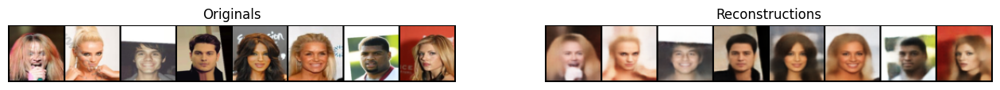

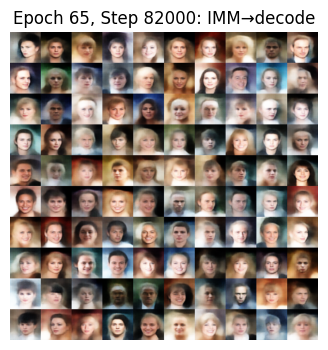

[Epoch 65/80  Step 82200]  Reconstruction=0.01637  MMD=0.01563 IMM=0.04860
[Epoch 65/80  Step 82400]  Reconstruction=0.01557  MMD=0.01562 IMM=0.07795
[Epoch 65/80  Step 82600]  Reconstruction=0.01703  MMD=0.01563 IMM=0.11653
[Epoch 66/80  Step 82800]  Reconstruction=0.01664  MMD=0.01576 IMM=0.04579
[Epoch 66/80  Step 83000]  Reconstruction=0.01634  MMD=0.01563 IMM=0.04603


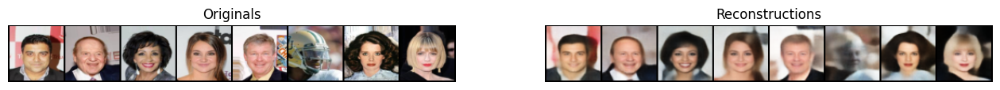

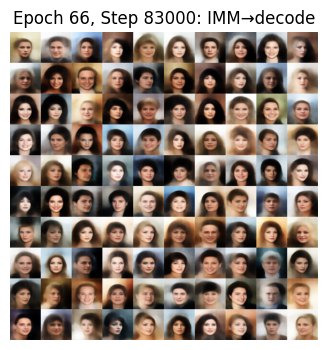

[Epoch 66/80  Step 83200]  Reconstruction=0.01641  MMD=0.01563 IMM=0.02185
[Epoch 66/80  Step 83400]  Reconstruction=0.01651  MMD=0.01563 IMM=0.05347
[Epoch 66/80  Step 83600]  Reconstruction=0.01562  MMD=0.01579 IMM=0.08239
[Epoch 66/80  Step 83800]  Reconstruction=0.01623  MMD=0.01562 IMM=0.10982
[Epoch 67/80  Step 84000]  Reconstruction=0.01567  MMD=0.01563 IMM=0.00980


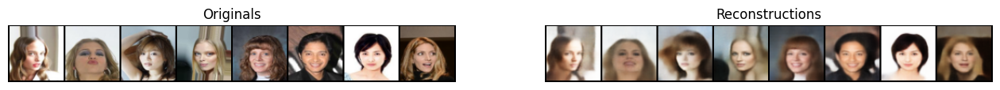

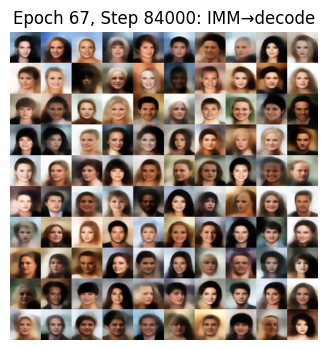

[Epoch 67/80  Step 84200]  Reconstruction=0.01565  MMD=0.01563 IMM=0.12579
[Epoch 67/80  Step 84400]  Reconstruction=0.01756  MMD=0.01563 IMM=0.05820
[Epoch 67/80  Step 84600]  Reconstruction=0.01633  MMD=0.01563 IMM=0.17065
[Epoch 67/80  Step 84800]  Reconstruction=0.01615  MMD=0.01563 IMM=0.07867
[Epoch 67/80  Step 85000]  Reconstruction=0.01703  MMD=0.01563 IMM=0.08517


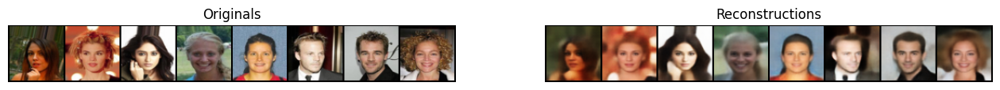

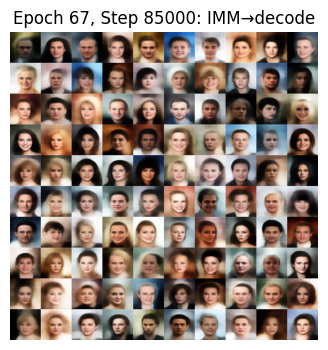

[Epoch 68/80  Step 85200]  Reconstruction=0.01654  MMD=0.01563 IMM=0.02857
[Epoch 68/80  Step 85400]  Reconstruction=0.01597  MMD=0.01563 IMM=0.07711
[Epoch 68/80  Step 85600]  Reconstruction=0.01496  MMD=0.01563 IMM=0.01008
[Epoch 68/80  Step 85800]  Reconstruction=0.01495  MMD=0.01563 IMM=0.06546
[Epoch 68/80  Step 86000]  Reconstruction=0.01608  MMD=0.01563 IMM=0.16374


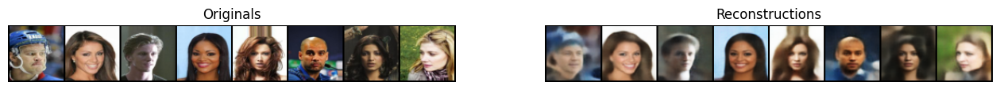

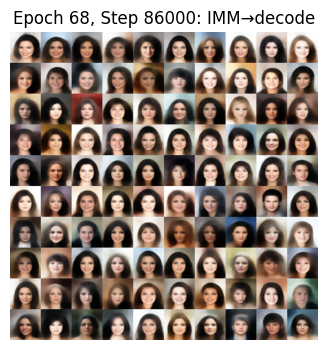

[Epoch 68/80  Step 86200]  Reconstruction=0.01717  MMD=0.01563 IMM=0.01676
[Epoch 68/80  Step 86400]  Reconstruction=0.01611  MMD=0.01562 IMM=0.12340
[Epoch 69/80  Step 86600]  Reconstruction=0.01634  MMD=0.01563 IMM=0.11189
[Epoch 69/80  Step 86800]  Reconstruction=0.01457  MMD=0.01563 IMM=0.04721
[Epoch 69/80  Step 87000]  Reconstruction=0.01568  MMD=0.01563 IMM=0.07181


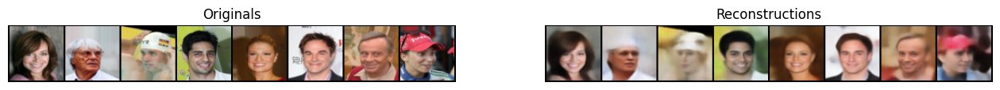

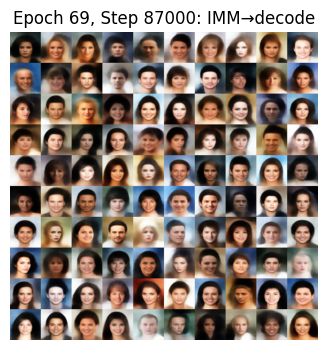

[Epoch 69/80  Step 87200]  Reconstruction=0.01516  MMD=0.01562 IMM=0.17371
[Epoch 69/80  Step 87400]  Reconstruction=0.01736  MMD=0.01563 IMM=0.03135
[Epoch 69/80  Step 87600]  Reconstruction=0.01630  MMD=0.01563 IMM=0.05902
[Epoch 70/80  Step 87800]  Reconstruction=0.01660  MMD=0.01562 IMM=0.11268
[Epoch 70/80  Step 88000]  Reconstruction=0.01665  MMD=0.01563 IMM=0.13943


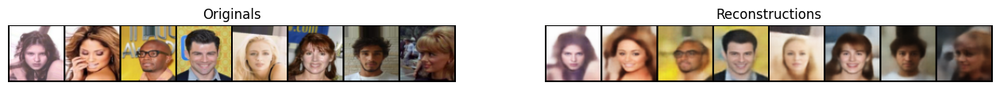

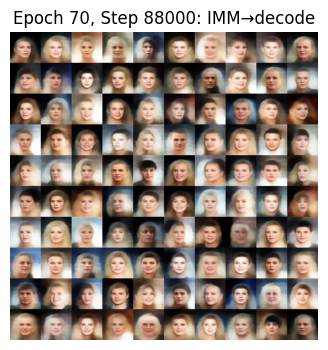

[Epoch 70/80  Step 88200]  Reconstruction=0.01676  MMD=0.01563 IMM=0.04725
[Epoch 70/80  Step 88400]  Reconstruction=0.01495  MMD=0.01562 IMM=0.09142
[Epoch 70/80  Step 88600]  Reconstruction=0.01602  MMD=0.01563 IMM=0.05528
[Epoch 70/80  Step 88800]  Reconstruction=0.01664  MMD=0.01562 IMM=0.14020
[Epoch 71/80  Step 89000]  Reconstruction=0.01651  MMD=0.01563 IMM=0.08728


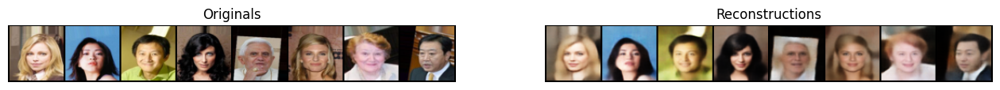

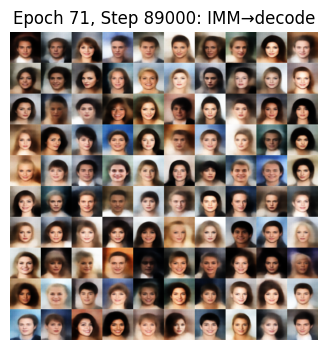

[Epoch 71/80  Step 89200]  Reconstruction=0.01543  MMD=0.01562 IMM=0.14310
[Epoch 71/80  Step 89400]  Reconstruction=0.01627  MMD=0.01563 IMM=0.04702
[Epoch 71/80  Step 89600]  Reconstruction=0.01530  MMD=0.01563 IMM=0.11840
[Epoch 71/80  Step 89800]  Reconstruction=0.01586  MMD=0.01562 IMM=0.06440
[Epoch 71/80  Step 90000]  Reconstruction=0.01715  MMD=0.01563 IMM=0.07110


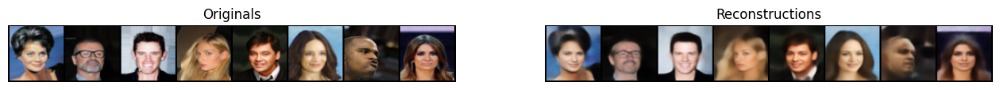

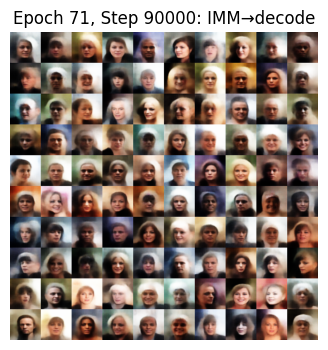

[Epoch 71/80  Step 90200]  Reconstruction=0.01682  MMD=0.01562 IMM=0.16244
[Epoch 72/80  Step 90400]  Reconstruction=0.01643  MMD=0.01563 IMM=0.18121
[Epoch 72/80  Step 90600]  Reconstruction=0.01557  MMD=0.01562 IMM=0.08439
[Epoch 72/80  Step 90800]  Reconstruction=0.01637  MMD=0.01562 IMM=0.04989
[Epoch 72/80  Step 91000]  Reconstruction=0.01576  MMD=0.01563 IMM=0.03936


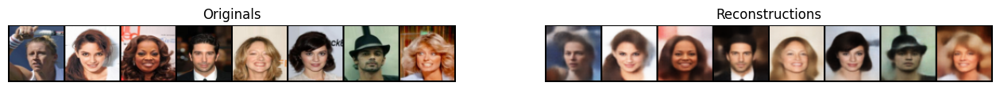

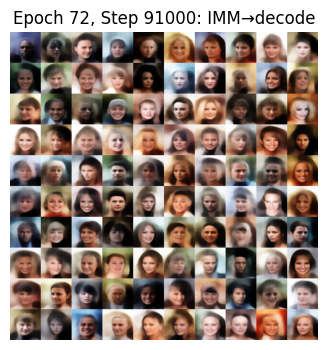

[Epoch 72/80  Step 91200]  Reconstruction=0.01551  MMD=0.01563 IMM=0.07568
[Epoch 72/80  Step 91400]  Reconstruction=0.01576  MMD=0.01563 IMM=0.12856
[Epoch 73/80  Step 91600]  Reconstruction=0.01485  MMD=0.01563 IMM=0.06960
[Epoch 73/80  Step 91800]  Reconstruction=0.01639  MMD=0.01562 IMM=0.09220
[Epoch 73/80  Step 92000]  Reconstruction=0.01504  MMD=0.01564 IMM=0.09892


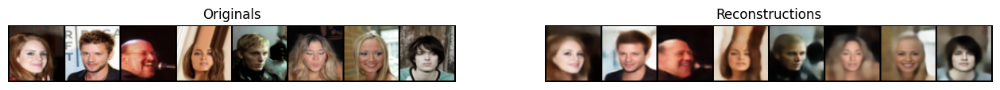

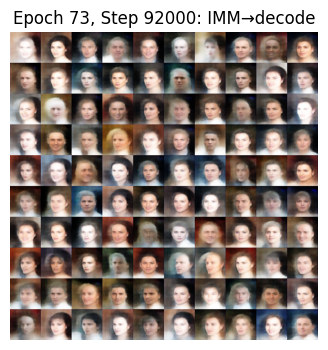

[Epoch 73/80  Step 92200]  Reconstruction=0.01599  MMD=0.01562 IMM=0.05564
[Epoch 73/80  Step 92400]  Reconstruction=0.01531  MMD=0.01563 IMM=0.06015
[Epoch 73/80  Step 92600]  Reconstruction=0.01575  MMD=0.01562 IMM=0.00219
[Epoch 74/80  Step 92800]  Reconstruction=0.01757  MMD=0.01562 IMM=0.08797
[Epoch 74/80  Step 93000]  Reconstruction=0.01543  MMD=0.01562 IMM=0.03109


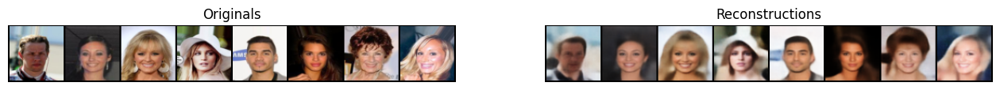

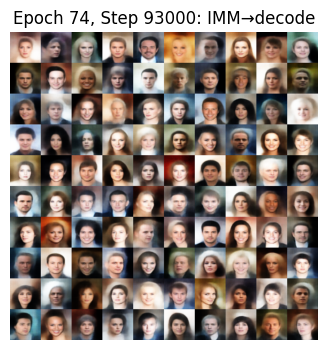

[Epoch 74/80  Step 93200]  Reconstruction=0.01553  MMD=0.01563 IMM=0.04964
[Epoch 74/80  Step 93400]  Reconstruction=0.01590  MMD=0.01562 IMM=0.06662
[Epoch 74/80  Step 93600]  Reconstruction=0.01496  MMD=0.01563 IMM=0.11274
[Epoch 74/80  Step 93800]  Reconstruction=0.01606  MMD=0.01563 IMM=0.09357
[Epoch 74/80  Step 94000]  Reconstruction=0.01784  MMD=0.01563 IMM=0.00980


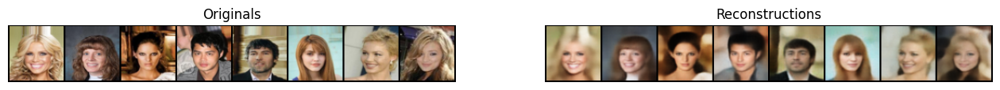

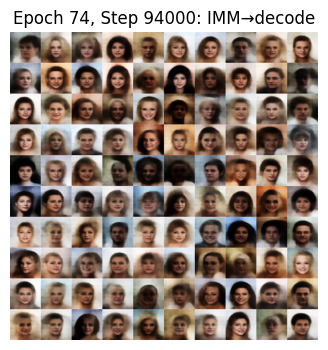

[Epoch 75/80  Step 94200]  Reconstruction=0.01500  MMD=0.01563 IMM=0.01373
[Epoch 75/80  Step 94400]  Reconstruction=0.01532  MMD=0.01563 IMM=0.08789
[Epoch 75/80  Step 94600]  Reconstruction=0.01577  MMD=0.01562 IMM=0.07970
[Epoch 75/80  Step 94800]  Reconstruction=0.01703  MMD=0.01562 IMM=0.01973
[Epoch 75/80  Step 95000]  Reconstruction=0.01553  MMD=0.01563 IMM=0.13545


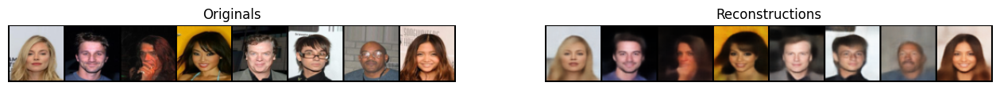

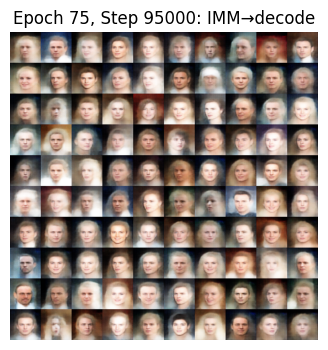

[Epoch 75/80  Step 95200]  Reconstruction=0.01659  MMD=0.01563 IMM=0.09451
[Epoch 76/80  Step 95400]  Reconstruction=0.01736  MMD=0.01563 IMM=0.08467
[Epoch 76/80  Step 95600]  Reconstruction=0.01651  MMD=0.01562 IMM=0.08887
[Epoch 76/80  Step 95800]  Reconstruction=0.01622  MMD=0.01563 IMM=0.02670
[Epoch 76/80  Step 96000]  Reconstruction=0.01678  MMD=0.01563 IMM=0.03814


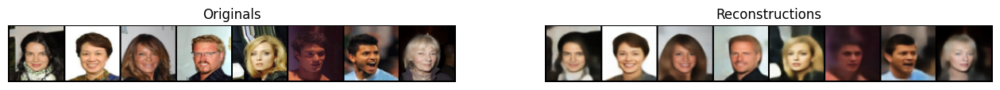

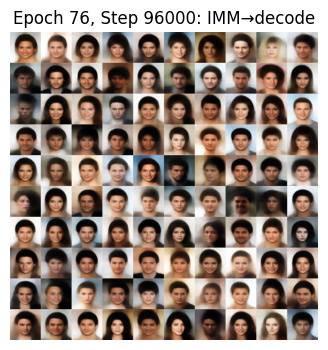

[Epoch 76/80  Step 96200]  Reconstruction=0.01746  MMD=0.01563 IMM=0.13531
[Epoch 76/80  Step 96400]  Reconstruction=0.01562  MMD=0.01562 IMM=0.05025
[Epoch 77/80  Step 96600]  Reconstruction=0.01598  MMD=0.01563 IMM=0.11151
[Epoch 77/80  Step 96800]  Reconstruction=0.01727  MMD=0.01562 IMM=0.06520
[Epoch 77/80  Step 97000]  Reconstruction=0.01567  MMD=0.01562 IMM=0.05101


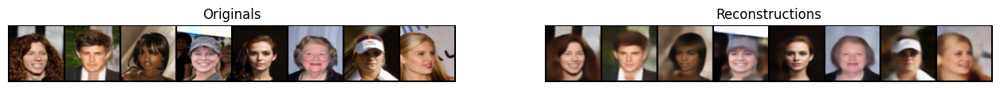

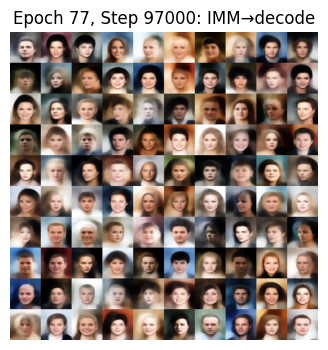

[Epoch 77/80  Step 97200]  Reconstruction=0.01555  MMD=0.01562 IMM=0.11607
[Epoch 77/80  Step 97400]  Reconstruction=0.01640  MMD=0.01563 IMM=0.03370
[Epoch 77/80  Step 97600]  Reconstruction=0.01548  MMD=0.01576 IMM=0.18096
[Epoch 77/80  Step 97800]  Reconstruction=0.01542  MMD=0.01563 IMM=0.11258
[Epoch 78/80  Step 98000]  Reconstruction=0.01522  MMD=0.01563 IMM=0.05231


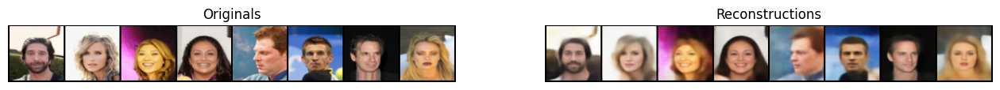

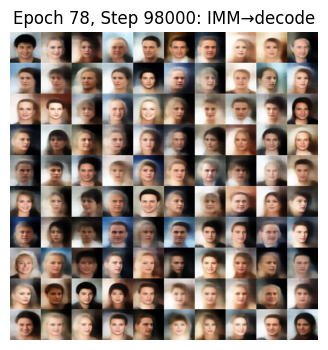

[Epoch 78/80  Step 98200]  Reconstruction=0.01552  MMD=0.01562 IMM=0.11120
[Epoch 78/80  Step 98400]  Reconstruction=0.01673  MMD=0.01562 IMM=0.18229
[Epoch 78/80  Step 98600]  Reconstruction=0.01549  MMD=0.01562 IMM=0.04968
[Epoch 78/80  Step 98800]  Reconstruction=0.01598  MMD=0.01562 IMM=0.03372
[Epoch 78/80  Step 99000]  Reconstruction=0.01610  MMD=0.01563 IMM=0.01012


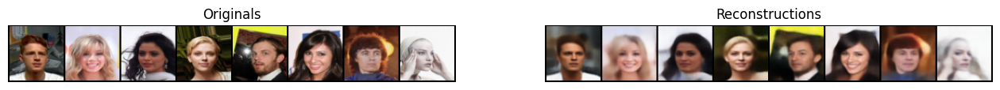

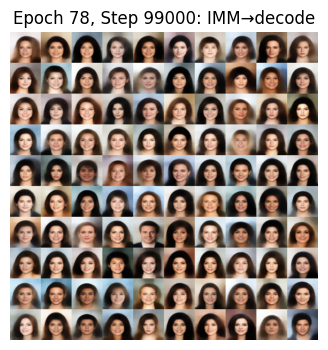

[Epoch 79/80  Step 99200]  Reconstruction=0.01554  MMD=0.01562 IMM=0.04325
[Epoch 79/80  Step 99400]  Reconstruction=0.01518  MMD=0.01562 IMM=0.09113
[Epoch 79/80  Step 99600]  Reconstruction=0.01589  MMD=0.01562 IMM=0.09849
[Epoch 79/80  Step 99800]  Reconstruction=0.01662  MMD=0.01563 IMM=0.11986
[Epoch 79/80  Step 100000]  Reconstruction=0.01715  MMD=0.01565 IMM=0.04743


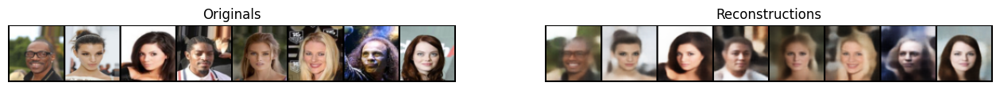

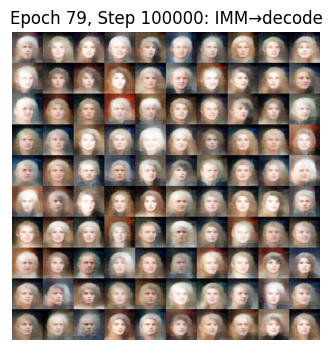

[Epoch 79/80  Step 100200]  Reconstruction=0.01712  MMD=0.01563 IMM=0.07235
[Epoch 79/80  Step 100400]  Reconstruction=0.01668  MMD=0.01563 IMM=0.04579
[Epoch 80/80  Step 100600]  Reconstruction=0.01537  MMD=0.01562 IMM=0.09565
[Epoch 80/80  Step 100800]  Reconstruction=0.01585  MMD=0.01562 IMM=0.04778
[Epoch 80/80  Step 101000]  Reconstruction=0.01535  MMD=0.01562 IMM=0.00466


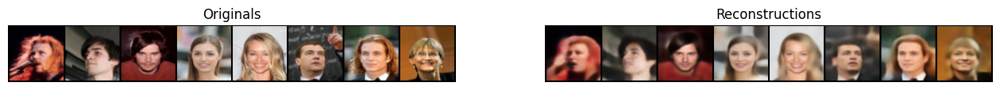

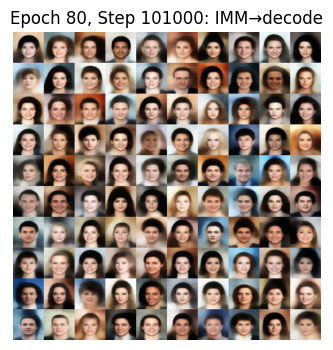

[Epoch 80/80  Step 101200]  Reconstruction=0.01512  MMD=0.01563 IMM=0.04085
[Epoch 80/80  Step 101400]  Reconstruction=0.01554  MMD=0.01562 IMM=0.06255
[Epoch 80/80  Step 101600]  Reconstruction=0.01620  MMD=0.01586 IMM=0.08178


In [4]:
# ────────────────────────────────────────────────────────────────
# 4) MMD computation (RBF kernel)
# ────────────────────────────────────────────────────────────────
def compute_kernel(x, y):
    x_size, y_size, dim = x.size(0), y.size(0), x.size(1)
    x_exp = x.unsqueeze(1).expand(x_size, y_size, dim)
    y_exp = y.unsqueeze(0).expand(x_size, y_size, dim)
    kernel_input = ((x_exp - y_exp)**2).mean(2) / float(dim)
    return torch.exp(-kernel_input)  # [x_size, y_size]

def compute_mmd(x, y):
    x_kernel = compute_kernel(x, x).mean()
    y_kernel = compute_kernel(y, y).mean()
    xy_kernel = compute_kernel(x, y).mean()
    return x_kernel + y_kernel - 2*xy_kernel

# ────────────────────────────────────────────────────────────────
# 5) The “pure” VAE (no KL, only MMD) wrapper
# ────────────────────────────────────────────────────────────────
# class Model(nn.Module):
#     def __init__(self,
#                  img_channels:     3,
#                  filters:          32,
#                  num_conv:         3,
#                  intermediate_dim: 128,
#                  z_dim:       2,
#                  img_rows:         32,
#                  img_cols:         32):
#         super().__init__()
#         # ← the order here must match your Encoder’s __init__
#         self.encoder = Encoder(
#             img_channels=img_channels,
#             filters=filters,
#             num_conv=num_conv,
#             intermediate_dim=intermediate_dim,
#             latent_dim=z_dim,
#             img_rows=img_rows,
#             img_cols=img_cols,
#         )
#         self.decoder = Decoder(
#             img_channels=img_channels,
#             filters=filters,
#             num_conv=num_conv,
#             intermediate_dim=intermediate_dim,
#             latent_dim=z_dim,
#             img_rows=img_rows,
#             img_cols=img_cols,
#         )

#     def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
#         # Optionally clamp logvar for stability
#         logvar = torch.clamp(logvar, min=-10.0, max=10.0)
#         std = (0.5 * logvar).exp()
#         eps = torch.randn_like(std)
#         return mu + eps * std

#     def forward(self, x: torch.Tensor):
#         mu, logvar = self.encoder(x)
#         z = self.reparameterize(mu, logvar)
#         x_recon = self.decoder(z)
#         return z, x_recon
# ────────────────────────────────────────────────────────────────
# 6) IMM schedule and parameterizations (OTFM Euler-FM version)
# ────────────────────────────────────────────────────────────────
class IMMSchedule(nn.Module):
    def alpha(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def sigma(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def lamb(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def lamb_diff(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def eta(self, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def eta_inv(self, u: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

class CosineSchedule(IMMSchedule):
    @property
    def tmax(self):
        return 0.996

    @property
    def tmin(self):
        return 0.001

    def alpha(self, t: torch.Tensor) -> torch.Tensor:
        return torch.cos(0.5 * math.pi * t)

    def sigma(self, t: torch.Tensor) -> torch.Tensor:
        return torch.sin(0.5 * math.pi * t)

    def lamb(self, t: torch.Tensor) -> torch.Tensor:
        return 2.0 * torch.log(1.0 / torch.tan(0.5 * math.pi * t))

    def lamb_diff(self, t: torch.Tensor) -> torch.Tensor:
        return -2.0 / torch.sin(math.pi * t)

    def eta(self, t: torch.Tensor) -> torch.Tensor:
        return torch.tan(0.5 * math.pi * t)

    def eta_inv(self, u: torch.Tensor) -> torch.Tensor:
        return 2.0 * torch.atan(u) / math.pi

class OTFMSchedule(IMMSchedule):
    @property
    def tmax(self):
        return 0.994
    @property
    def tmin(self):
        return 0.001

    def alpha(self, t: torch.Tensor) -> torch.Tensor:
        return 1.0 - t
    def sigma(self, t: torch.Tensor) -> torch.Tensor:
        return t
    def lamb(self, t: torch.Tensor) -> torch.Tensor:
        return 2.0 * torch.log((1.0 - t) / t)
    def lamb_diff(self, t: torch.Tensor) -> torch.Tensor:
        return 2.0 / (t*t - t)
    def eta(self, t: torch.Tensor) -> torch.Tensor:
        return t / (1.0 - t)
    def eta_inv(self, u: torch.Tensor) -> torch.Tensor:
        return u / (u + 1.0)

class IMMParameterization(nn.Module):
    def __init__(self, sigma_data: float, schedule: IMMSchedule):
        super().__init__()
        self.sigma_data = sigma_data
        self.schedule = schedule

    def c_noise(self, t: torch.Tensor) -> torch.Tensor:
        return 1000.0 * t

    def c_in(self, t: torch.Tensor) -> torch.Tensor:
        a = self.schedule.alpha(t)
        s = self.schedule.sigma(t)
        return 1.0 / (self.sigma_data * torch.sqrt(a*a + s*s))

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError
    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        raise NotImplementedError

class OtFmEulerFmParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        super().__init__(sigma_data, OTFMSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # always 1
        return torch.ones_like(s)

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # -(t - s) * sigma_data
        return -(t - s) * self.sigma_data

class OtFmIdentityParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        super().__init__(sigma_data, OTFMSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # sigma_s / sigma_t
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        return σ_s / σ_t

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # alpha_s − alpha_t * (σ_s/σ_t)
        α_s = self.schedule.alpha(s)
        α_t = self.schedule.alpha(t)
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        return α_s - α_t * (σ_s / σ_t)

class CosineIdentityParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        super().__init__(sigma_data, CosineSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        sigma_s = self.schedule.sigma(s)
        sigma_t = self.schedule.sigma(t)
        return sigma_s / sigma_t

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        alpha_s = self.schedule.alpha(s)
        alpha_t = self.schedule.alpha(t)
        sigma_s = self.schedule.sigma(s)
        sigma_t = self.schedule.sigma(t)
        return alpha_s - alpha_t * sigma_s / sigma_t

class CosineSimpleEDMParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        # uses the CosineSchedule defined above
        super().__init__(sigma_data, CosineSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # cos(½π (t−s))
        return torch.cos(0.5 * math.pi * (t - s))

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # − sin(½π (t−s)) · σ_data
        return -torch.sin(0.5 * math.pi * (t - s)) * self.sigma_data

class OtFmSimpleEDMParameterization(IMMParameterization):
    def __init__(self, sigma_data: float):
        # uses the Linear OTFM schedule defined above
        super().__init__(sigma_data, OTFMSchedule())

    def c_skip(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        a_s = self.schedule.alpha(s)
        a_t = self.schedule.alpha(t)
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        # (a_s a_t + σ_s σ_t) / (a_t² + σ_t²)
        return (a_s * a_t + σ_s * σ_t) / (a_t**2 + σ_t**2)

    def c_out(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        a_s = self.schedule.alpha(s)
        a_t = self.schedule.alpha(t)
        σ_s = self.schedule.sigma(s)
        σ_t = self.schedule.sigma(t)
        # −(a_s σ_t − σ_s a_t) / √(a_t² + σ_t²)  · σ_data
        return -(a_s*σ_t - σ_s*a_t) / torch.sqrt(a_t**2 + σ_t**2) * self.sigma_data

# ────────────────────────────────────────────────────────────────
# 7) Small MLP builder to feed (x_t * c_in(t), c_noise(s), c_noise(t)) → D
# ────────────────────────────────────────────────────────────────
def get_mlp(hidden_dim: int, n_hidden: int, input_dim: int, output_dim: int) -> nn.Module:
    layers = []
    in_dim = input_dim
    for _ in range(n_hidden):
        layers.append(nn.Linear(in_dim, hidden_dim))
        layers.append(nn.Mish())
        in_dim = hidden_dim
    layers.append(nn.Linear(hidden_dim, output_dim))
    return nn.Sequential(*layers)

class ResBlock(nn.Module):
    """A single residual block: LayerNorm → Linear → SiLU → Linear → skip."""
    def __init__(self, dim):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1  = nn.Linear(dim, dim * 2)
        self.fc2  = nn.Linear(dim * 2, dim)
        self.act  = nn.SiLU()

    def forward(self, x):
        h = self.norm(x)
        h = self.act(self.fc1(h))
        h = self.fc2(h)
        return x + h

class ResidualDenoiser(nn.Module):
    """
    Residual MLP denoiser for IMM.

    Input:  [B, D+2]  →  project up
    Middle: N × ResBlock(dim)
    Output: project back to [B, D]
    """
    def __init__(self,
                 input_dim:  int,
                 model_dim:  int = 1024,
                 n_blocks:   int = 8,
                 output_dim: int = None):
        super().__init__()
        output_dim = output_dim or (input_dim - 2)  # D = input_dim-2
        # initial projection
        self.project_in  = nn.Sequential(
            nn.Linear(input_dim, model_dim),
            nn.SiLU()
        )
        # residual blocks
        self.blocks = nn.ModuleList([ResBlock(model_dim) for _ in range(n_blocks)])
        # final projection
        self.project_out = nn.Sequential(
            nn.LayerNorm(model_dim),
            nn.SiLU(),
            nn.Linear(model_dim, output_dim)
        )

    def forward(self, x):
        # x: [B, D+2]
        h = self.project_in(x)           # [B, model_dim]
        for block in self.blocks:
            h = block(h)                 # [B, model_dim]
        return self.project_out(h)       # [B, D]

# ────────────────────────────────────────────────────────────────
# 8) The IMM model (general latent‐dimension D = z_dim)
# ────────────────────────────────────────────────────────────────
class IMM(nn.Module):
    def __init__(self,
                 network: nn.Module,
                 parameterization: IMMParameterization,
                 a: int = 1,
                 b: int = 4,
                 eta_max: float = 160.0,
                 eta_min: float = 1e-8,
                 k: int = 12,
                 M: int = 16,
                 D: int = 2):
        """
        network: a small MLP mapping R^(D+2) → R^D
        parameterization: e.g. OtFmEulerFmParameterization(sigma_data)
        a, b, eta_max, eta_min, k, M: hyperparams
        D: latent dimension (e.g. 2 or 32)
        """
        super().__init__()
        self.network = network
        self.parameterization = parameterization
        self.schedule = parameterization.schedule

        self.D = D
        self.a = a
        self.b = b
        self.eta_max = eta_max
        self.eta_min = eta_min
        self.k = k
        self.M = M

    def forward(self, x_t: torch.Tensor, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # x_t: [B, D], s,t: [B,1]
        skip = self.parameterization.c_skip(s, t) * x_t  # [B, D]

        # Build model input = [ x_t * c_in(t), c_noise(s), c_noise(t) ]
        c_in_t = self.parameterization.c_in(t)       # [B, 1]
        x_scaled = x_t * c_in_t                       # [B, D]
        noise_s = self.parameterization.c_noise(s)    # [B, 1]
        noise_t = self.parameterization.c_noise(t)    # [B, 1]
        inp = torch.cat([x_scaled, noise_s, noise_t], dim=-1)  # [B, D+2]

        out = self.network(inp)                               # [B, D]
        out = self.parameterization.c_out(s, t) * out         # [B, D]
        return skip + out

    def _ddim(self,
              x_source: torch.Tensor,
              x_target: torch.Tensor,
              s: torch.Tensor,
              t: torch.Tensor) -> torch.Tensor:
        # x_source @ time t, x_target @ time 0 → produce x @ time s
        a_s = self.schedule.alpha(s)   # [B,1]
        a_t = self.schedule.alpha(t)   # [B,1]
        sig_s = self.schedule.sigma(s) # [B,1]
        sig_t = self.schedule.sigma(t) # [B,1]

        term1 = (a_s - (sig_s / sig_t) * a_t) * x_target    # [B, D]
        term2 = (sig_s / sig_t) * x_source                 # [B, D]
        return term1 + term2

    def _kernel(self,
                x: torch.Tensor,
                y: torch.Tensor,
                s: torch.Tensor,
                t: torch.Tensor) -> torch.Tensor:
        # Pairwise kernel between x and y at times s < t
        eps = 1e-8
        c_out_st = self.parameterization.c_out(s, t)           # [N,1]
        w = torch.abs(1.0 / (c_out_st + eps))                   # [N,1]

        diff = x - y                                           # [N, D]
        dist = torch.norm(diff, p=2, dim=-1).clamp(min=eps)     # [N,]
        w_flat = w.view_as(dist)                               # [N,]
        log_k = -w_flat * dist / float(self.D)                  # [N,]

        mask = (t.view(-1) > s.view(-1))                        # [N,]
        return torch.where(mask, torch.exp(log_k), torch.zeros_like(log_k))  # [N,]

    def _kernel_for_diff(self,
                         difference: torch.Tensor,
                         s: torch.Tensor,
                         t: torch.Tensor) -> torch.Tensor:
        zeros = torch.zeros_like(difference)
        return self._kernel(difference, zeros, s.unsqueeze(-1), t.unsqueeze(-1))

    def _weight_fn(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # s,t: [N,1]
        t_flat = t.view(-1)                             # [N,]
        a_t = self.schedule.alpha(t).view(-1)           # [N,]
        sig_t = self.schedule.sigma(t).view(-1)         # [N,]
        logSNR_t = self.schedule.lamb(t).view(-1)       # [N,]
        dlogSNR_t = self.schedule.lamb_diff(t).view(-1) # [N,]

        coef = 0.5 * torch.sigmoid(self.b - logSNR_t) * (-dlogSNR_t)  # [N,]
        denom = a_t.pow(2) + sig_t.pow(2)                              # [N,]
        num = a_t.pow(self.a)                                         # [N,]
        return coef * num / denom                                     # [N,]

    def _map_fn(self, s: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        eps = (self.eta_max - self.eta_min) / (2 ** self.k)
        eta_t = self.schedule.eta(t)                 # [B,1]
        val = eta_t - eps
        inv = self.schedule.eta_inv(val)             # [B,1]
        return torch.maximum(s, inv)                  # [B,1]

    def compute_loss(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: [B, D], B must be divisible by M
        returns: scalar joint IMM loss
        """
        B = x.shape[0]
        M = self.M
        assert B % M == 0, f"Batch size ({B}) not divisible by M ({M})"

        G = B // M  # number of groups
        # 1) sample z_prior ~ N(0, σ_data² I) at t=1
        z_prior = self.parameterization.sigma_data * torch.randn_like(x)

        # 2) sample t_single ∈ [tmin, tmax], s_single ∈ [tmin, t_single]
        t_range = self.schedule.tmax - self.schedule.tmin
        t_single = torch.rand((G, 1), device=x.device) * t_range + self.schedule.tmin  # [G,1]
        s_single = torch.rand((G, 1), device=x.device) * (t_single - self.schedule.tmin) + self.schedule.tmin  # [G,1]

        # 3) repeat each M‐times → [B,1]
        t = t_single.repeat_interleave(M, dim=0)  # [B,1]
        s = s_single.repeat_interleave(M, dim=0)  # [B,1]

        # 4) r = map_fn(s, t)
        r = self._map_fn(s, t)  # [B,1]

        # 5) x_t = ddim(z_prior, x, t, 1)
        one_t = torch.ones_like(t)           # [B,1]
        x_t = self._ddim(z_prior, x, t, one_t)  # [B, D]

        # 6) x_r = ddim(x_t, x, r, t)
        x_r = self._ddim(x_t, x, r, t)       # [B, D]

        # 7) f_x_t, f_x_r
        f_x_t = self.forward(x_t, s, t)      # [B, D]
        f_x_r = self.forward(x_r, s, r).detach()  # [B, D]

        # 8) reshape to [G, M, D]
        f_x_t = f_x_t.view(G, M, self.D)     # [G, M, D]
        f_x_r = f_x_r.view(G, M, self.D)     # [G, M, D]

        # 9) pairwise differences (G × M × M × D)
        diff1 = (f_x_t.unsqueeze(1) - f_x_t.unsqueeze(2)).reshape(G*M*M, self.D)
        diff2 = (f_x_r.unsqueeze(1) - f_x_r.unsqueeze(2)).reshape(G*M*M, self.D)
        diff3 = (f_x_t.unsqueeze(1) - f_x_r.unsqueeze(2)).reshape(G*M*M, self.D)

        # 10) build ss, ts, rs arrays of length G*M*M
        ss = s_single.repeat_interleave(M*M, dim=0).view(-1)  # [G*M*M,]
        ts = t_single.repeat_interleave(M*M, dim=0).view(-1)  # [G*M*M,]
        rs = self._map_fn(ss.unsqueeze(-1), ts.unsqueeze(-1)).view(-1)  # [G*M*M,]

        # 11) compute kernel terms
        term1 = self._kernel_for_diff(diff1, ss, ts)  # [G*M*M,]
        term2 = self._kernel_for_diff(diff2, ss, rs)  # [G*M*M,]
        term3 = -2.0 * self._kernel_for_diff(diff3, ss, ts)  # [G*M*M,]

        # 12) weights
        weights = self._weight_fn(ss.unsqueeze(-1), ts.unsqueeze(-1))  # [G*M*M,]

        joint = term1 + term2 + term3  # [G*M*M,]
        return torch.mean(joint * weights)

    def sample(self, n_samples: int, times: torch.Tensor) -> torch.Tensor:
        """
        times: 1D tensor in descending order, e.g. [1.0, 0.9, ..., tmin]
        returns: [n_samples, D] latents at t=tmin
        """
        device = next(self.parameters()).device
        x = self.parameterization.sigma_data * torch.randn((n_samples, self.D), device=device)
        for i in range(len(times) - 1):
            t_val = times[i]
            s_val = times[i+1]
            t_tensor = torch.full((n_samples, 1), t_val, device=device)
            s_tensor = torch.full((n_samples, 1), s_val, device=device)
            x = self.forward(x, s_tensor, t_tensor)
        return x  # [n_samples, D]

# ────────────────────────────────────────────────────────────────
# 9) Utility to tile [batch,28,28,1] → grid image
# ────────────────────────────────────────────────────────────────
def convert_to_display(samples: np.ndarray) -> np.ndarray:
    """
    Tile a batch of images into a square grid.
    samples: [B, H, W, C], B must be a perfect square.
    Returns: [H*grid, W*grid, C].
    """
    B, H, W, C = samples.shape
    cnt = int(math.sqrt(B))
    assert cnt*cnt == B, "batch size must be a perfect square"
    # first reshape into (grid_y, grid_x, H, W, C)
    grid = samples.reshape(cnt, cnt, H, W, C)
    # swap axes to (grid_y, H, grid_x, W, C)
    grid = grid.transpose(0, 2, 1, 3, 4)
    # merge to (grid_y*H, grid_x*W, C)
    grid = grid.reshape(cnt * H, cnt * W, C)
    return grid
# ────────────────────────────────────────────────────────────────
# 10) to visualize the reconstructed images
# ────────────────────────────────────────────────────────────────
# def show_reconstructions(model, dataloader, device, n=8):
#     """
#     Grab one batch from dataloader, run it through model,
#     and plot the first n originals vs reconstructions.
#     """
#     model.eval()
#     # grab a single batch
#     imgs, _ = next(iter(dataloader))
#     imgs = imgs.to(device)

#     # forward pass
#     with torch.no_grad():
#         z, recon = model(imgs)        # or: recon, mu, logvar = model(imgs)
#     # take first n
#     origs = imgs[:n]
#     recs  = recon[:n]

#     # make two image-grids
#     grid_orig = torchvision.utils.make_grid(origs.cpu(), nrow=n, normalize=True)
#     grid_recon= torchvision.utils.make_grid(recs.cpu(),  nrow=n, normalize=True)

#     # plot
#     plt.figure(figsize=(2*n,4))
#     plt.subplot(1,2,1)
#     plt.title("Originals")
#     plt.axis("off")
#     plt.imshow(np.transpose(grid_orig, (1,2,0)))
#     plt.subplot(1,2,2)
#     plt.title("Reconstructions")
#     plt.axis("off")
#     plt.imshow(np.transpose(grid_recon, (1,2,0)))
#     plt.show()

#     model.train()
def show_reconstructions(model, dataloader, device, n=8):
    """
    Grab one batch from dataloader, run it through model,
    and plot the first n originals vs reconstructions,
    denormalizing from [-1,1] → [0,1].
    """
    model.eval()
    # grab a single batch
    imgs, _ = next(iter(dataloader))
    imgs = imgs.to(device)

    # forward pass
    with torch.no_grad():
        z, recon = model(imgs)

    # take first n
    origs = imgs[:n].cpu()
    recs  = recon[:n].cpu()

    # undo Normalize(mean=0.5,std=0.5): x_denorm = x*0.5 + 0.5
    origs = origs * 0.5 + 0.5
    recs  = recs  * 0.5 + 0.5

    # clamp just in case of numerical overshoot
    origs = origs.clamp(0, 1)
    recs  = recs.clamp(0, 1)

    # make two image-grids (no internal normalization)
    grid_orig  = torchvision.utils.make_grid(origs, nrow=n)
    grid_recon = torchvision.utils.make_grid(recs,  nrow=n)

    # plot
    plt.figure(figsize=(2*n, 4))
    plt.subplot(1, 2, 1)
    plt.title("Originals")
    plt.axis("off")
    plt.imshow(np.transpose(grid_orig, (1, 2, 0)))
    plt.subplot(1, 2, 2)
    plt.title("Reconstructions")
    plt.axis("off")
    plt.imshow(np.transpose(grid_recon, (1, 2, 0)))
    plt.show()

    model.train()


# ────────────────────────────────────────────────────────────────
# 10) The combined “MMD + IMM” training loop
# ────────────────────────────────────────────────────────────────
def train(
    dataloader,
    z_dim=2,
    n_epochs=10,
    use_cuda=True,
    print_every=100,
    plot_every=500
):
    device = torch.device("cuda" if (torch.cuda.is_available() and use_cuda) else "cpu")
    print("Current CUDA device:", torch.cuda.current_device(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "n/a")

    # 10.1) Instantiate IMM (D = z_dim, M = 16)
    parametrization = OtFmEulerFmParameterization(sigma_data=1.0)
    #imm_net = get_mlp(hidden_dim=256, n_hidden=6, input_dim=z_dim+2, output_dim=z_dim).to(device)
    #imm_net = get_mlp(hidden_dim=2048, n_hidden=32, input_dim=z_dim+2, output_dim=z_dim)
    imm_net = ResidualDenoiser(input_dim = z_dim + 2, model_dim = 1024, n_blocks  = 8, output_dim= z_dim) #.to(device)
    imm_model = IMM(
        network=imm_net,
        parameterization=parametrization,
        a=1, b=4, eta_max=160.0, eta_min=1e-8, k=12, M=32,
        D=z_dim
    ).to(device)

    # 10.2) Instantiate the VAE (Encoder + Decoder)
    #model = Model(3, 32, 3, 128, z_dim, 32, 32).to(device)
    # 10.2) Instantiate the plain Autoencoder for 64×64 CelebA
    model = Autoencoder(
        img_channels=3,
        filters=64,
        kernel_size=3,
        intermediate_dim=512,
        latent_dim=z_dim,
        img_rows=image_size,
        img_cols=image_size,
                        ).to(device)

    # 10.3) Two optimizers: VAE params and IMM params
    optimizer_vae = torch.optim.Adam(model.parameters(), lr=1e-3)
    optimizer_imm = torch.optim.Adam(imm_model.parameters(), lr=1e-5)

    step_idx = 0
    for epoch in range(n_epochs):
        model.train()
        imm_model.train()

        for images, _labels in dataloader:
            step_idx += 1

            # ─── Zero gradients for both optimizers ───
            # optimizer_vae.zero_grad()
            # optimizer_imm.zero_grad()

            # ─── Move batch to device ───
            x = images.to(device)  # [B,1,28,28]

            # ─── Forward pass through VAE ───
            z, x_recon = model(x)  # z: [B, z_dim], x_recon: [B,1,28,28]
            z_det = z.detach()

            # (1) Reconstruction loss (MSE)
            nll = F.mse_loss(x_recon, x, reduction='mean')

            # (2) MMD term: sample “true” N(0,1) latents of size [B, z_dim]
            B = z.shape[0]
            # Ensure B is divisible by IMM.M=16
            assert B % imm_model.M == 0, f"Batch size ({B}) must be divisible by IMM.M ({imm_model.M})"
            true_samples = torch.randn((B, z_dim), device=device)
            mmd = compute_mmd(true_samples, z)

            n_samples = z.shape[0]           # match batch size
            times = torch.linspace(1.0,
            imm_model.schedule.tmin,
            steps=32,
            device=device)   # e.g. [1.0,0.857,0.714,…,0.0]

            # Now sample z_imm ∈ R^{B×z_dim} using the learned IMM denoiser
            z_imm = imm_model.sample(n_samples, times)  # [B, z_dim]

            # (b) Prior‐matching MMD between z_enc and z_imm
            prior_mmd = compute_mmd(z_imm, z)

            # (3) IMM joint‐loss on z
            imm_loss = imm_model.compute_loss(z_det)

            # (4) Total loss = reconstruction + 0.1*mmd + imm_loss
            #loss = nll + .1*prior_mmd + 1e-2*imm_loss
            loss_vae = nll +  1e-5 * mmd #1* prior_mmd +
            loss_imm_net = 1 * imm_loss

            optimizer_vae.zero_grad()
            optimizer_imm.zero_grad()

            # Backprop both objectives on the same graph:
            loss_vae.backward(retain_graph=True)   # keep the graph alive so IMM can still use it
            loss_imm_net.backward()

            # Now that both backward() calls have run, update both optimizers:
            optimizer_vae.step()
            optimizer_imm.step()
            # (5) Backpropagate both
            # loss.backward()
            # optimizer.step()
            # optimizer_imm.step()

            if step_idx % print_every == 0:
                print(
                    f"[Epoch {epoch+1}/{n_epochs}  Step {step_idx}]  "
                    f"Reconstruction={nll.item():.5f}  MMD={prior_mmd.item():.5f} IMM={imm_loss.item():.5f}" #IMM={imm_loss.item():.5f}
                )

            # ─── Every plot_every steps: sample new digits via IMM → decode → show ───
            if step_idx % plot_every == 0:
                imm_model.eval()
                #Show reconstructions of real batch
                show_reconstructions(model, dataloader, device, n=8)
                with torch.no_grad():
                    n_vis = 100
                    times = torch.linspace(
                        1.0,
                        imm_model.schedule.tmin,
                        steps=32,
                        device=device
                    )
                    gen_z = imm_model.sample(n_vis, times)       # [100, z_dim]
                    #gen_z = torch.randn(100, z_dim, device=device)      # [100, z_dim]
                    samples = model.decoder(gen_z)                # [100,1,28,28]
                    # ---- Denormalize from [-1,1] → [0,1] ----
                    samples = samples.cpu()
                    samples = samples * 0.5 + 0.5    # if you used Normalize(0.5,0.5) during training
                    samples = samples.clamp(0, 1)

                    samples_np = samples.permute(0, 2, 3, 1).numpy()  # [B, H, W, 3]
                    display_img = convert_to_display(samples_np)
                    plt.figure(figsize=(4,4))
                    plt.imshow(display_img)      # matplotlib auto‐detects RGB
                    plt.title(f"Epoch {epoch+1}, Step {step_idx}: IMM→decode")
                    plt.axis("off")
                    plt.show()

                imm_model.train()

    return model, imm_model

# ────────────────────────────────────────────────────────────────
# 11) Run training in Colab
# ────────────────────────────────────────────────────────────────
if __name__ == "__main__":
    set_seed(42)
    # 11.1) Build a DataLoader whose batch_size is divisible by 16, and drop the last incomplete batch
    torch.cuda.set_device(1)
    batch_size = 128  # 192 % 16 == 0
    image_size = 64    # target spatial size (64×64)
    # 2) Define CelebA transform pipeline
    celeba_transform = transforms.Compose([
        transforms.Resize((image_size, image_size)),   # scale shorter side then center‐crop
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5],      # map to [–1,1]
                             std =[0.5, 0.5, 0.5]),
    ])
    celeba_train = DataLoader(
        CelebA("./data/CelebA", split='train', download=True, transform = celeba_transform),
        batch_size = batch_size,
        shuffle = True,
        drop_last = True,    # ← drop any partial final batch
        num_workers = 0,     # reduce to 2 to avoid “too many workers” warning
        pin_memory = True
    )

    # 11.2) Train for z_dim=2 and 10 epochs
    z_dim = 128
    vae_model, imm_model = train(
        dataloader = celeba_train,
        z_dim = z_dim,
        n_epochs = 80,
        use_cuda = True,
        print_every = 200,
        plot_every = 1000
    )

    # After this finishes, you have:
    #   - `vae_model` (the trained VAE)
    #   - `imm_model` (the trained IMM)
    # You can now perform inference exactly as described earlier (reconstruction or generating new samples).